# 🛠️ 정정 안내 (Audit 반영본)
> 이 노트북은 원본 보고서에 **감사(Audit)에서 발견한 4가지 과장/불일치를 정정**한 버전입니다. 정정 표시(🛠️ [Audit 정정])가 붙은 박스를 참고하세요.
>
> 1. **모델 선택:** "ElasticNet이 가장 견고/최고" → 세 규제 모델은 fold 표준편차 대비 **통계적으로 동등**, 단순성 기반 선택으로 정정
> 2. **변수 중요도:** "Total SF가 핵심 요인" → 실제 1순위는 **입지·건물유형**(수정본에서 계수 산출). 파생변수는 최종 모델에 누락돼 있었음
> 3. **Rare 병합:** 실제 미동작(dead code)이었음을 명시, 수정본은 `OneHotEncoder(min_frequency)`로 구현
> 4. **검증:** CV 낙관편향을 Nested CV로 보완. 단, **Private Test M 0.8708(2위), Gap 1.0%**로 일반화는 외부 검증됨
>
> 누수 없는 완전 재구현은 `notebooks/01_final_model_corrected.ipynb` 참조.

---


# 🏡 수치형 변수를 이용한 회귀 예측 모델 구축
### : 주택 가격 예측 보고서

> **프로젝트 과정:** `1. 프로젝트 개요` $\to$ `2. 데이터 이해` $\to$ `3. 데이터 전처리` $\to$ `4. 모델링 및 성능 평가` $\to$ `5. 모델 평가 및 해석`

---

## 1. 프로젝트 개요

### 1.1 문제 정의 및 목표
* **배경:** 주택 가격은 다양한 요인이 복합적으로 작용하므로, **데이터 기반의 객관적 평가 모델** 필요

* **목표:** Ames Housing 데이터를 활용하여 가격 결정 요인을 분석하고, **신뢰도 높은 회귀 예측** 모델을 구축하고자 함

### 1.2 목표 세부 설정

1.  **🎯 정확한 가격 예측**
    * 실제 거래 가격과의 오차를 최소화하여 예측의 정밀도를 높임

2.  **🔍 가격 결정 요인 해석**
    * 가격 변동에 영향을 미치는 **주요 변수**를 파악하고 해석

3.  **🛡️ 일반화된 모델 확보**
    * 특정 데이터에만 잘 맞는 **과적합을 방지**하여, 새로운 데이터에도 안정적으로 예측하는 모델을 개발

------------------------------------------------------------------------------------------------

##### 준비 과정
- 변수 변환, 필요한 변수 선택, 환경 설정, 파일 불러오기

In [1]:
# 변수 변환
reg_map = {
    'SalePrice': 'sale_price',
    'Overall Qual': 'overall_qual',
    'Overall Cond': 'overall_cond',
    'Neighborhood': 'neighborhood',
    'Gr Liv Area': 'gr_liv_area',
    'MS Zoning': 'ms_zoning',
    'Lot Area': 'lot_area',
    'Lot Frontage': 'lot_frontage',
    'Total Bsmt SF': 'total_bsmt_sf',
    'Year Built': 'year_built',
    'Year Remod/Add': 'year_remod_add',
    'Yr Sold': 'yr_sold',
    'Full Bath': 'full_bath',
    'Half Bath': 'half_bath',
    'Bedroom AbvGr': 'bedroom_abv_gr',
    'Kitchen Qual': 'kitchen_qual',
    'Garage Type': 'garage_type',
    'Garage Finish': 'garage_finish',
    'Garage Cars': 'garage_cars',
    'Bsmt Qual': 'bsmt_qual',
    'Bsmt Exposure': 'bsmt_exposure',
    'BsmtFin Type 1': 'bsmt_fin_type1',
    'Exter Qual': 'exter_qual',
    'Heating QC': 'heating_qc',
    'Fireplace Qu': 'fireplace_qu',
    'Central Air': 'central_air',
    'Fireplaces': 'fireplaces',
    'Paved Drive': 'paved_drive',
    'Open Porch SF': 'open_porch_sf',
    'Bldg Type': 'bldg_type',
    'Sale Condition': 'sale_condition'
}

In [2]:
# --------------------------------------------
# 필요한 변수 선택1
# --------------------------------------------
import pandas as pd

src = './regression_train_public.csv'
df = pd.read_csv(src)
df.columns = df.columns.str.strip()  # 공백 제거
df = df.rename(columns=reg_map)
# 재공지_v2.md의 [규칙 2]에 따라, 학습에 사용하지 않는 나머지 50개 컬럼은 여기서 미리 제거
df = df[list(reg_map.values())]  # 31개 변수만 선택
df.to_csv('regression_train_public_renamed.csv', index=False)

# --------------------------------------------
# 필요한 변수 선택2
# --------------------------------------------
import pandas as pd

src = './regression_test_private.csv'
df = pd.read_csv(src)
df.columns = df.columns.str.strip()  # 공백 제거
df = df.rename(columns=reg_map)
# 재공지_v2.md의 [규칙 2]에 따라, 학습에 사용하지 않는 나머지 50개 컬럼은 여기서 미리 제거
df = df[[c for c in reg_map.values() if c in df.columns]]  # 존재하는 변수만 선택(30개)
df.to_csv('regression_test_private_renamed.csv', index=False)


In [3]:
# --------------------------------------------
# 환경 설정 (라이브러리 & 기본 설정)
# --------------------------------------------
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge, Lasso, ElasticNet
from sklearn.model_selection import GridSearchCV, KFold

plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.size'] = 11

# --------------------------------------------
# 한글 폰트 설정
# --------------------------------------------
plt.rcParams["font.family"] = "AppleGothic" # Apple
plt.rcParams["font.family"] = "Malgun Gothic" # Windows
plt.rcParams["axes.unicode_minus"] = False # 한글 폰트 사용 시 깨짐 방지

print("라이브러리 임포트 완료")

# --------------------------------------------
# 파일 불러오기
# --------------------------------------------
df_train = pd.read_csv("regression_train_public_renamed.csv")
df_test = pd.read_csv("regression_test_private_renamed.csv")

라이브러리 임포트 완료


------------------------------------------------------------------------------------------------

## 2. 데이터 이해 및 탐색
   - 💡 전처리를 수행하기 앞서, 데이터의 물리적 구조와 통계적 분포를 파악하여 전처리 전략을 수립했습니다.
   > **과정:** `1. 데이터 구조 및 기초 통계` $\to$ `2. EDA` $\to$ `3. 데이터 품질 진단`

------------------------------------------------------------------------------------------------

## 2.1 데이터 구조 및 기초 통계
* **목적:** 전체 데이터 규모와 변수 타입(수치형 16개, 범주형 15개)을 분류하여, **전처리 방향성** 수립

* **접근:** `shape`, `info()`

### - 데이터 구성 요약

1.  **기본 정보 확인**
    - 2,344개 관측치, 31개 변수 (수치형 16개, 범주형 15개)
2.  **변수 타입 분류**
    * **수치형 변수:** `SalePrice`, `Lot Area` ~
        * 연산이 가능한 변수로, 이상치 확인 및 **스케일링** 대상
    * **범주형 변수:** `Neighborhood`, `House Style`~
        * 텍스트나 그룹으로 된 변수로, **원-핫 인코딩** 등의 변환 필요

In [4]:
# ==========================================
# 1. 기본 정보 확인
# ==========================================

print(f"📊 데이터 크기: {df_train.shape}")
print(f"   - 전체 행 수: {df_train.shape[0]}개")
print(f"   - 전체 변수 수: {df_train.shape[1]}개")

# 기초 통계량 확인
print("\n[수치형 변수 기초 통계량]")
display(df_train.describe().T.round(2)) # 컬럼이 많을 때, .T를 사용하여 한 눈에 보기 쉽게 출력


📊 데이터 크기: (2344, 31)
   - 전체 행 수: 2344개
   - 전체 변수 수: 31개

[수치형 변수 기초 통계량]


,count,mean,std,min,25%,50%,75%,max
sale_price,2344.0,178582.21,77125.07,12789.0,129000.00,160000.0,210000.00,755000.0
overall_qual,2344.0,6.06,1.39,1.0,5.00,6.0,7.00,10.0
overall_cond,2344.0,5.58,1.11,1.0,5.00,5.0,6.00,9.0
gr_liv_area,2344.0,1492.86,504.62,334.0,1121.75,1436.5,1734.00,5642.0
lot_area,2344.0,10127.86,8050.91,1300.0,7466.50,9356.5,11484.25,215245.0
lot_frontage,1951.0,69.21,23.42,21.0,58.00,68.0,80.00,313.0
total_bsmt_sf,2343.0,1047.02,436.57,0.0,784.00,988.0,1288.00,6110.0
year_built,2344.0,1970.51,30.34,1872.0,1953.00,1972.0,2000.00,2010.0
year_remod_add,2344.0,1983.92,20.79,1950.0,1965.00,1992.0,2003.00,2010.0
yr_sold,2344.0,2007.79,1.32,2006.0,2007.00,2008.0,2009.00,2010.0


In [5]:
# ==========================================
# 2. 변수 타입 분류
# ==========================================

# 수치형과 범주형 분리
num_cols = df_train.select_dtypes(include=['int64', 'float64']).columns.tolist()
cat_cols = df_train.select_dtypes(include=['object']).columns.tolist()

# 요약 정보를 데이터프레임으로 생성
dtype_summary = pd.DataFrame({
    '구분': ['수치형 변수', '범주형 변수'],
    '개수': [f"{len(num_cols)}개", f"{len(cat_cols)}개"],
    '대표 변수 예시': [f"{num_cols[:3]} ...", f"{cat_cols[:3]} ..."]
})

print("\n📋 [변수 타입별 요약표]")
display(dtype_summary)


📋 [변수 타입별 요약표]


,구분,개수,대표 변수 예시
0,수치형 변수,16개,"['sale_price', 'overall_qual', 'overall_cond']..."
1,범주형 변수,15개,"['neighborhood', 'ms_zoning', 'kitchen_qual'] ..."


## 2.2 EDA - 타켓 변수(SalePrice) 분석
* **목적:** 타겟 변수의 분포 특성을 확인하고, 상관관계 분석을 통해 가격 예측의 **핵심 변수** 도출

* **접근:** 히스토그램, 상관계수 행렬, 산점도를 통해 시각적으로 검증

### - 주요 분석 결과 요약

1.  **📈 타겟 변수(SalePrice) 분포 확인**

    * 왜도 측정 결과, 양의 왜도(1.75)
    
         -> 고가 주택에 의해 왜곡될 위험 존재, 정규분포 근사를 위해 **로그 변환** 필요성 검토
2.  **🔗 상관관계 분석**

    * 타겟 변수와 선형적 관계가 강한 **예측 변수** 도출 및 시각화
    
         -> Overall Qual · Gr Live Area, 높은 양의 상관관계
    
         -> **집 값**은 **품질**과 **크기**의 영향력이 강함, 모델링에서 **가장 중요한 예측 변수**로 작용할 것을 의미

3. **수치형 및 범주형 분포 확인**

    1. **📊 수치형 변수**

        * **면적 변수:** `Gr Liv Area` 등은 오른쪽으로 치우친 분포
    
            -> 이상치 영향 완화 및 정규성 확보를 위해 **로그 변환** 적용 고려
    
        * **등급 변수:** `Overall Qual`은 수치형이지만 불연속적 분포
    
            -> **순서형 변수**로 취급하여 등급 간 가중치 부여 필요

    2.  **🏘️ 범주형 변수**

         * **품질:** 등급(Ex > Gd > TA...)에 따라 평균 집값의 **계단식 차이**가 뚜렷
    
            -> **순서형 인코딩**을 통해 서열 정보를 모델에 주입 필요
    
        * **동네:** 지역별 가격 편차가 크며, 특정 부촌이 존재
    
            -> 지역 특성을 반영한 인코딩 필요


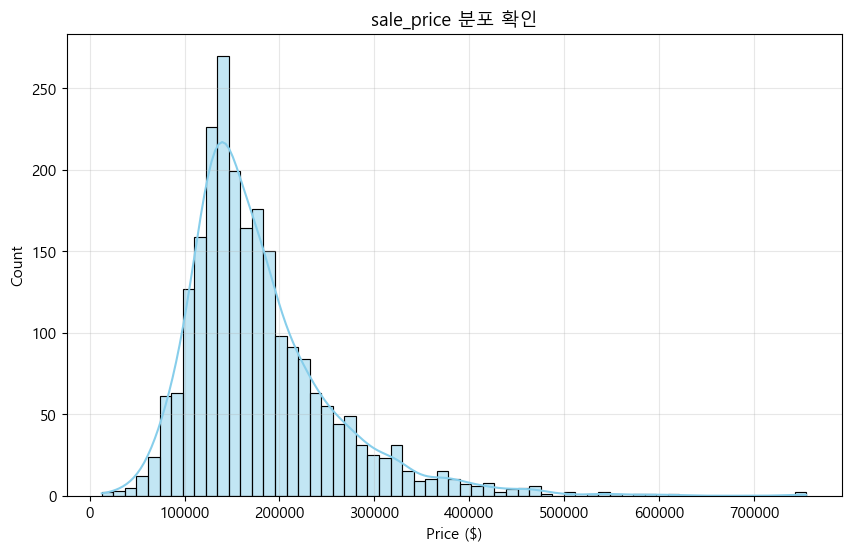

📊 sale_price 왜도(Skewness): 1.75
💡 해석: 0보다 큰 양의 왜도를 가짐. 즉, 데이터가 왼쪽으로 쏠려 있고 꼬리가 오른쪽으로 김.


In [6]:
# ==========================================
# 1. 타겟 변수(SalePrice) 분포 확인
# ==========================================

target_col = "sale_price"
plt.figure(figsize=(10, 6))

# 히스토그램과 커널 밀도(kde) 선 표시
sns.histplot(df_train[target_col], kde=True, color='skyblue')

plt.title(f"{target_col} 분포 확인")
plt.xlabel("Price ($)")
plt.ylabel("Count")
plt.grid(True, alpha=0.3)
plt.show()

# [결과 해석]
skew_val = df_train[target_col].skew() # 왜도
print(f"📊 {target_col} 왜도(Skewness): {skew_val:.2f}") # 해석

if skew_val > 0:
    print("💡 해석: 0보다 큰 양의 왜도를 가짐. 즉, 데이터가 왼쪽으로 쏠려 있고 꼬리가 오른쪽으로 김.")
else:
    print("💡 해석: 데이터가 대칭에 가깝거나 음의 왜도를 가짐.")

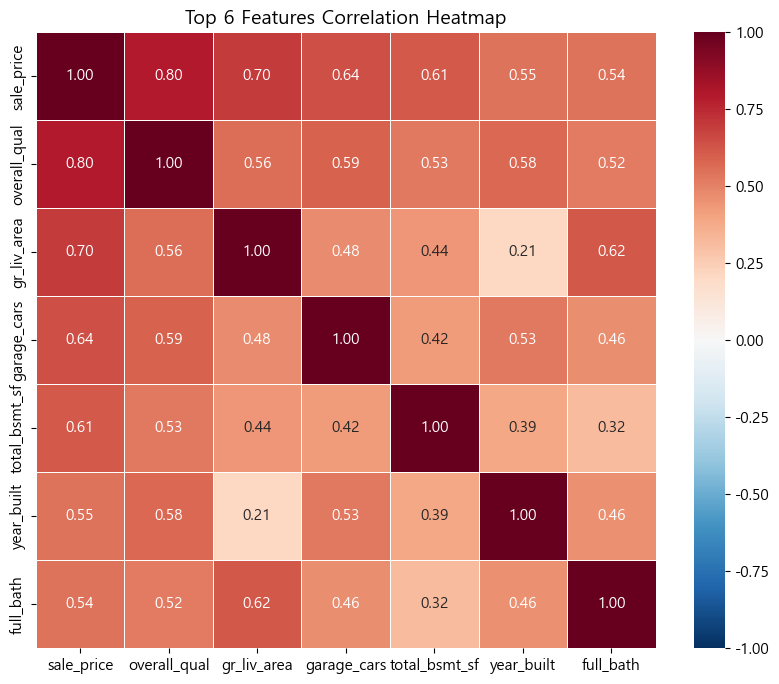

💡 히트맵 해석:
1. 붉은색이 진할수록 타겟(sale_price)과 강한 양의 상관관계를 가짐.
2. 'Overall Qual'과 'Gr Liv Area' 등이 주로 붉은색을 띠며 높은 상관관계를 보임.

📈 sale_price와 상관관계 상위 6개 수치형 변수:
overall_qual     0.795298
gr_liv_area      0.698315
garage_cars      0.644304
total_bsmt_sf    0.612256
year_built       0.545409
full_bath        0.542053
Name: sale_price, dtype: float64


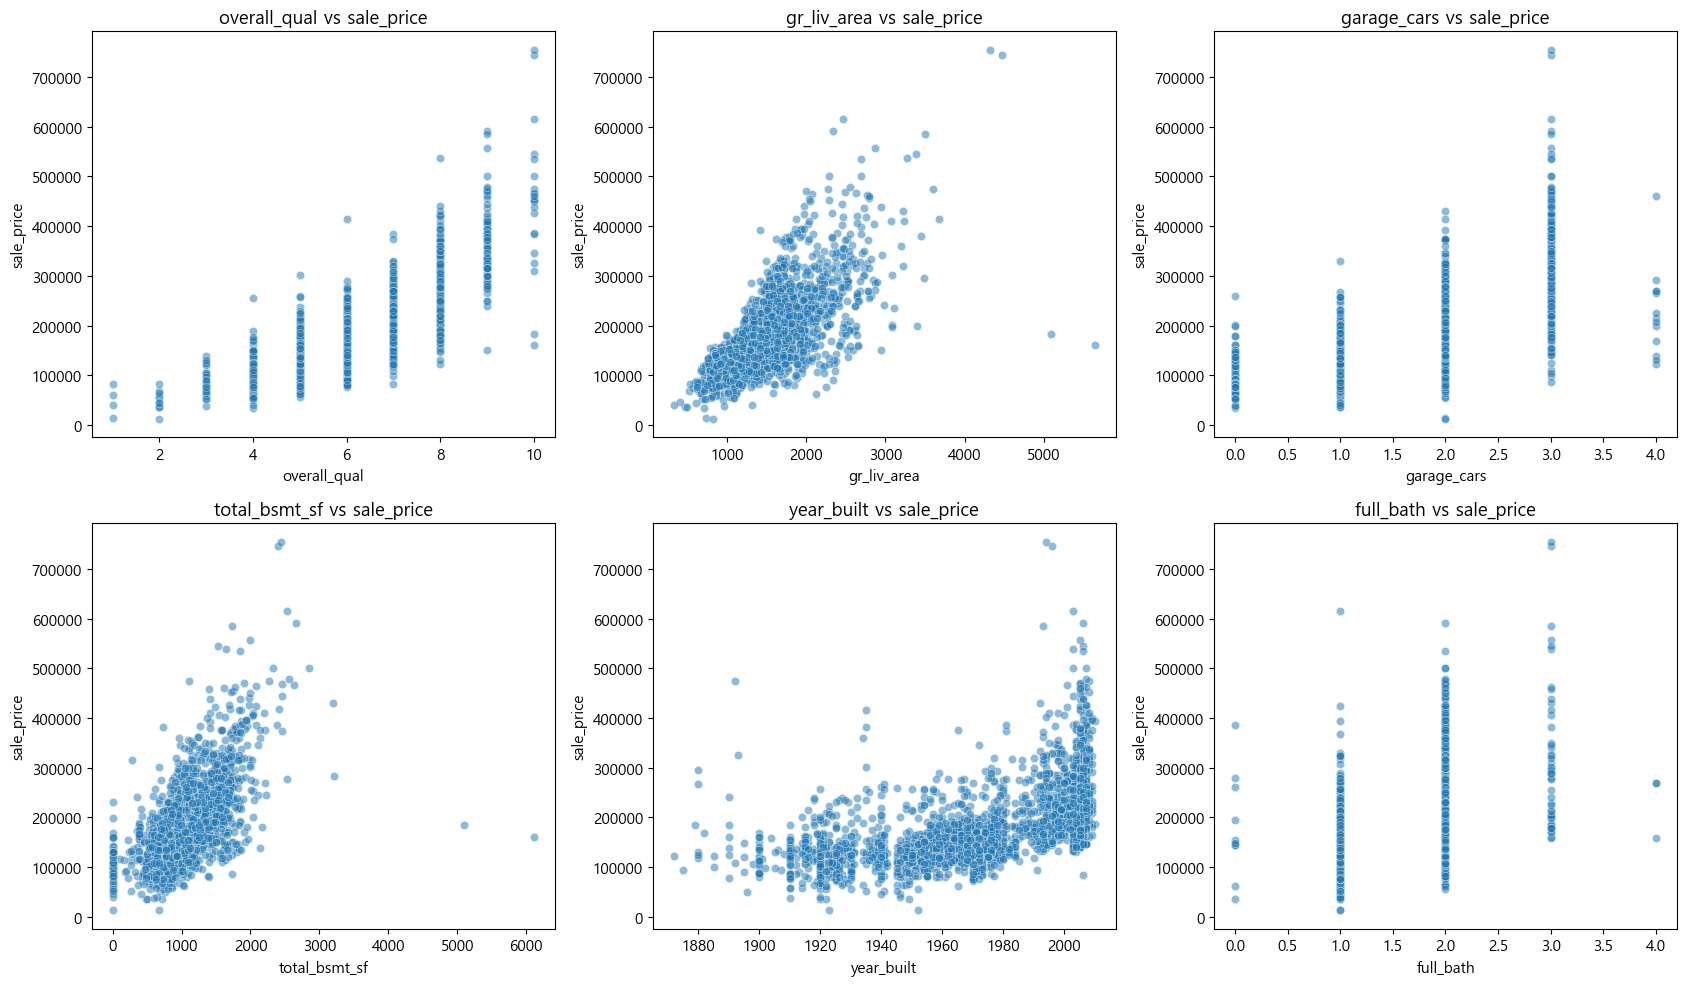

In [7]:
# ==========================================
# 2. 상관관계 분석
# ==========================================

target_col = 'sale_price'  # 타겟 변수명 정의

# 수치형 변수만 선택
numeric_df = df_train.select_dtypes(include=['number'])

# 상관계수 계산
# numeric_df 안에 SalePrice가 포함되어 있으므로 바로 계산
corr_series = numeric_df.corr()[target_col].sort_values(ascending=False)

# 상위 7개 변수명 추출
top_corr_features = corr_series.head(7).index.tolist()

# 상위 변수들 간의 상관계수 행렬 (히트맵용)
corr_matrix_top = df_train[top_corr_features].corr()

# 히트맵 그리기
plt.figure(figsize=(10, 8))

sns.heatmap(
    corr_matrix_top, 
    annot=True,         # 칸 안에 상관계수 숫자 표시
    fmt='.2f',          # 소수점 2자리까지 표시
    cmap='RdBu_r',      # 빨간색(+) ~ 파란색(-) 색상 맵
    center=0,           # 0을 기준으로 색상 나눔
    vmin=-1, vmax=1,    # 상관계수 범위 (-1 ~ 1) 고정
    linewidths=0.5      # 칸 사이 구분선
)

plt.title("Top 6 Features Correlation Heatmap", fontsize=14)
plt.show()

# [결과 해석]
print("💡 히트맵 해석:")
print(f"1. 붉은색이 진할수록 타겟({target_col})과 강한 양의 상관관계를 가짐.")
print("2. 'Overall Qual'과 'Gr Liv Area' 등이 주로 붉은색을 띠며 높은 상관관계를 보임.")

# ------------------------------------------

# 타겟 변수(SalePrice)를 제외한 상위 6개 변수 리스트 생성
top_features_no_target = [col for col in top_corr_features if col != target_col][:6]

print(f"\n📈 {target_col}와 상관관계 상위 6개 수치형 변수:")
print(corr_series[top_features_no_target])

# 상관 높은 상위 6개 변수와 타겟 변수의 산점도
cols = 3
n = len(top_features_no_target)
rows = (n + cols - 1) // cols 

fig, axes = plt.subplots(rows, cols, figsize=(17, 5 * rows))
axes = axes.flatten()

for i, col in enumerate(top_features_no_target):
    sns.scatterplot(x=df_train[col], y=df_train[target_col], alpha=0.5, ax=axes[i])
    axes[i].set_title(f"{col} vs {target_col}")
    axes[i].set_xlabel(col)
    axes[i].set_ylabel(target_col)

# 남는 빈칸 제거
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

📌 선정된 핵심 설명변수: ['overall_qual', 'gr_liv_area', 'garage_cars', 'total_bsmt_sf', 'year_built', 'full_bath']


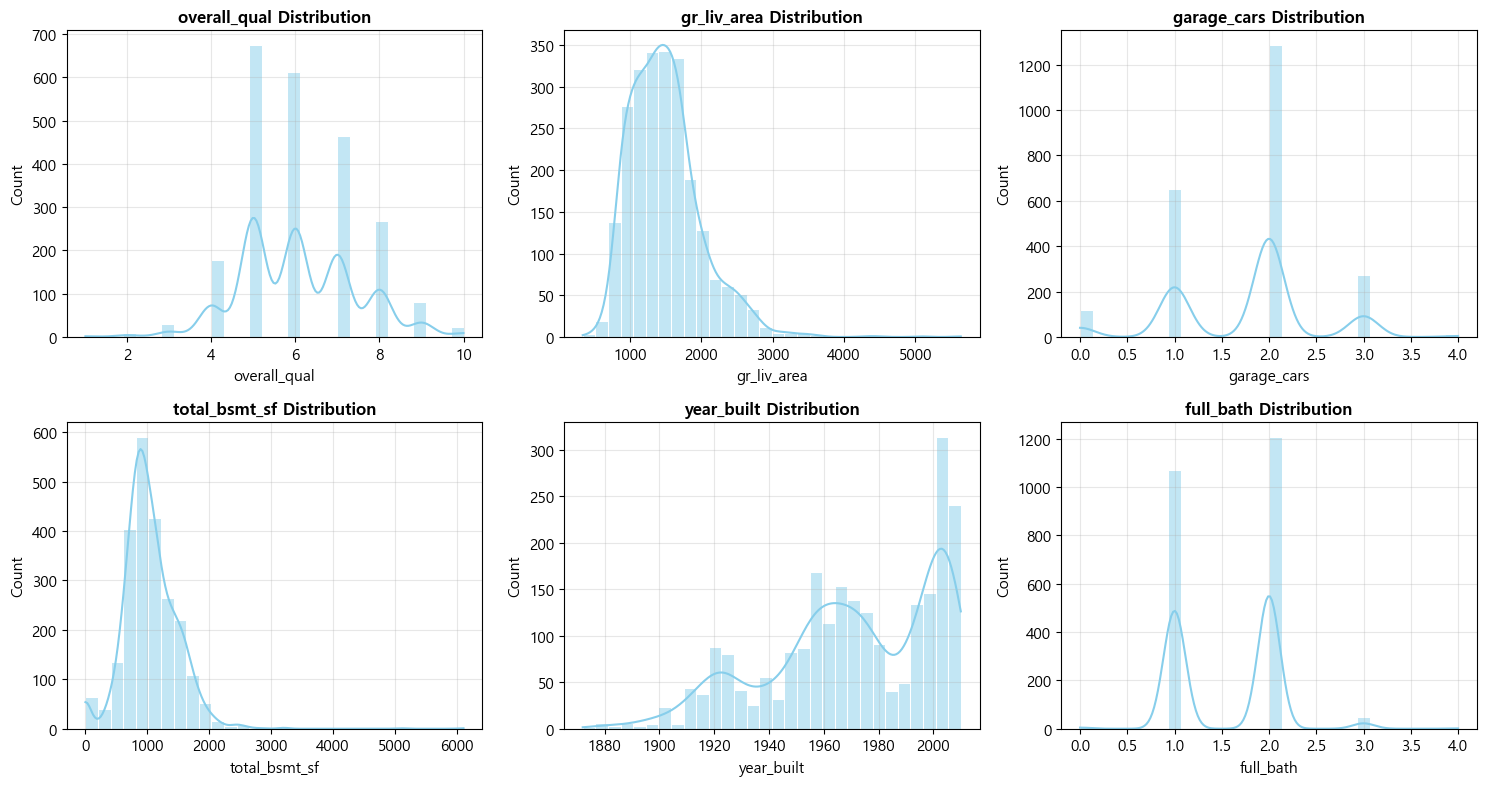

💡 해석:
1. 'Overall Qual'은 범주형 성격이 강해 불연속적인 분포를 보임.
2. 'Gr Liv Area'와 'Total Bsmt SF'는 오른쪽 꼬리가 긴 분포를 보임.
3. 대부분의 핵심 변수가 정규분포와 유사한 형태를 띠고 있어 회귀 분석에 적합함.


In [8]:
# ==========================================
# 3.1 수치형 변수 분포 시각화 (SalePrice 제외)
# ==========================================

# 수치형 변수만 선택
numeric_df = df_train.select_dtypes(include=['int64', 'float64'])

# 타겟 변수(sale_price) 제외하고, 상관계수 상위 6개 추출
top_6_cols = numeric_df.corr()['sale_price'].abs().sort_values(ascending=False).drop('sale_price').head(6).index

print(f"📌 선정된 핵심 설명변수: {top_6_cols.tolist()}")

# 시각화
plt.figure(figsize=(15, 8)) 

for i, col in enumerate(top_6_cols):
    plt.subplot(2, 3, i + 1)
    
    # 히스토그램과 KDE(밀도 곡선) 그리기
    sns.histplot(df_train[col], kde=True, bins=30, color='skyblue', edgecolor='white')
    
    plt.title(f'{col} Distribution', fontsize=12, fontweight='bold')
    plt.xlabel(col)
    plt.ylabel('Count')
    plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# [결과 해석]
print("💡 해석:")
print("1. 'Overall Qual'은 범주형 성격이 강해 불연속적인 분포를 보임.")
print("2. 'Gr Liv Area'와 'Total Bsmt SF'는 오른쪽 꼬리가 긴 분포를 보임.")
print("3. 대부분의 핵심 변수가 정규분포와 유사한 형태를 띠고 있어 회귀 분석에 적합함.")

📌 시각화 대상 변수 (6개): ['neighborhood', 'exter_qual', 'bsmt_qual', 'kitchen_qual', 'garage_type', 'heating_qc']


C:\Users\jiwoo\AppData\Local\Temp\ipykernel_10756\3493790818.py:29: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_train, y=col, x='sale_price', order=order_idx, palette='viridis')
C:\Users\jiwoo\AppData\Local\Temp\ipykernel_10756\3493790818.py:29: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_train, y=col, x='sale_price', order=order_idx, palette='viridis')
C:\Users\jiwoo\AppData\Local\Temp\ipykernel_10756\3493790818.py:29: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_train, y=col, x='sale_price', order=order_idx, pa

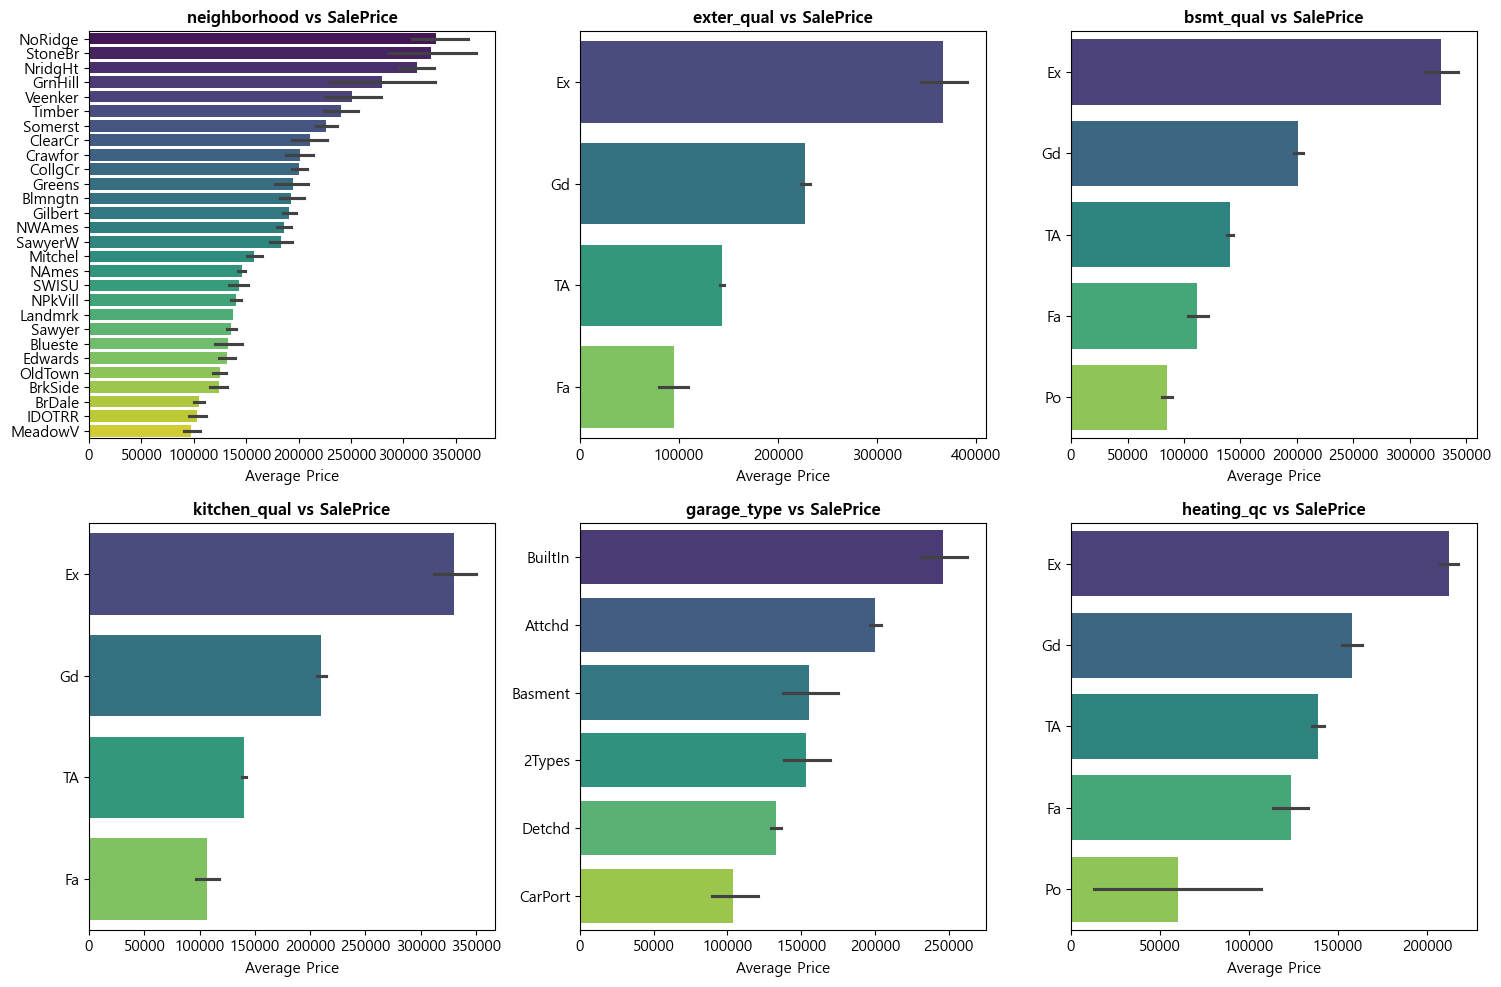

💡 해석:
1. [순서] 위쪽에 위치한 카테고리일수록 평균 집값이 높음.
2. [편차] 막대 끝의 검은 선(신뢰구간)이 짧을수록 가격이 평균 근처에 밀집해 있다는 뜻임.


In [9]:
# ==========================================
# 3.2 범주형 변수와 타겟(SalePrice) 관계 시각화
# ==========================================
import matplotlib.pyplot as plt
import seaborn as sns

# 분석할 주요 범주형 변수 후보군
candidate_cats = ['neighborhood', 'exter_qual', 'bsmt_qual', 'kitchen_qual', 'garage_type', 'foundation', 'heating_qc']

# 실제 데이터에 존재하는 컬럼만 필터링 (오류 방지)
valid_cats = [col for col in candidate_cats if col in df_train.columns]

# 상위 6개만 선택
top_cats = valid_cats[:6]

print(f"📌 시각화 대상 변수 ({len(top_cats)}개): {top_cats}")


# 시각화 (2행 3열)
plt.figure(figsize=(15, 10))

for i, col in enumerate(top_cats):
    plt.subplot(2, 3, i + 1)
    
    # [Logic] 평균 집값이 높은 순서대로 정렬 (가독성 확보)
    order_idx = df_train.groupby(col)['sale_price'].mean().sort_values(ascending=False).index
    
    # 막대 그래프 그리기
    sns.barplot(data=df_train, y=col, x='sale_price', order=order_idx, palette='viridis')
    
    plt.title(f'{col} vs SalePrice', fontsize=12, fontweight='bold')
    plt.xlabel('Average Price')
    plt.ylabel('')

plt.tight_layout()
plt.show()

# [결과 해석]
print("💡 해석:")
print("1. [순서] 위쪽에 위치한 카테고리일수록 평균 집값이 높음.")
print("2. [편차] 막대 끝의 검은 선(신뢰구간)이 짧을수록 가격이 평균 근처에 밀집해 있다는 뜻임.")

## 2.3 데이터 품질 진단
* **목적:** 데이터의 결측치 및 이상치를 파악하여, **삭제 여부**와 **모델링 전략**을 수립

* **접근:**
    1. 변수별 결측 비율을 계산하여 단순 '시설 없음'인지 '데이터 누락'인지 구분
    2. 주요 변수의 극단값 비율과 영향력을 평가하여 처리 방향 결정

### - 품질 분석 결과 요약

1.  **🗑️ 결측치 진단**
    * 대부분의 변수는 결측이 거의 없는 깨끗한 상태
    * **주요 결측 변수:** `Fireplace Qu` (49%), `Lot Frontage` (17%), `Garage Type/Finish` (5%)
    
       ->`Fireplace Qu` 등은 '시설 없음'을 의미하므로, **Lot Frontage**만 **처리 대상**으로 식별

2.  **⚠️ 이상치 특성 분석**
    * **`Overall Cond` (8%):** 단순 분포 차이로 판단 -> 이상치로서의 의미는 낮음

    * **`Gr Liv Area` (3%):** 종속변수에 강한 영향을 끼치는 변수 -> **예측 왜곡 가능성** 있음

    * **`SalePrice` (5%):** 분포의 편향 관찰됨-> **스케일링** 필수적
    
    * **`Lot Area` (5%):** 평균값과의 스케일 차이가 큼 -> **모델 가중치에 영향**을 줄 수 있음

3.  **🛡️ 최종 처리 전략**
    * 극단값이 일부 존재하나 비율이 낮아 무조건적인 **삭제 지양**

    * **[전략]** 고가·대형 주택의 특성 정보 손실을 막기 위해, **규제 모델**을 활용하여 이상치의 영향력만 **완충**하는 방향 채택


📋 [결측률 상위 10개 변수 현황]


,dtype,n_unique,missing_cnt,missing_rate
fireplace_qu,object,5,1144,0.488055
lot_frontage,float64,120,393,0.167662
garage_finish,object,3,122,0.052048
garage_type,object,6,120,0.051195
bsmt_exposure,object,4,63,0.026877
bsmt_qual,object,5,61,0.026024
bsmt_fin_type1,object,6,61,0.026024
total_bsmt_sf,float64,936,1,0.000427
garage_cars,float64,5,1,0.000427
lot_area,int64,1634,0,0.000000


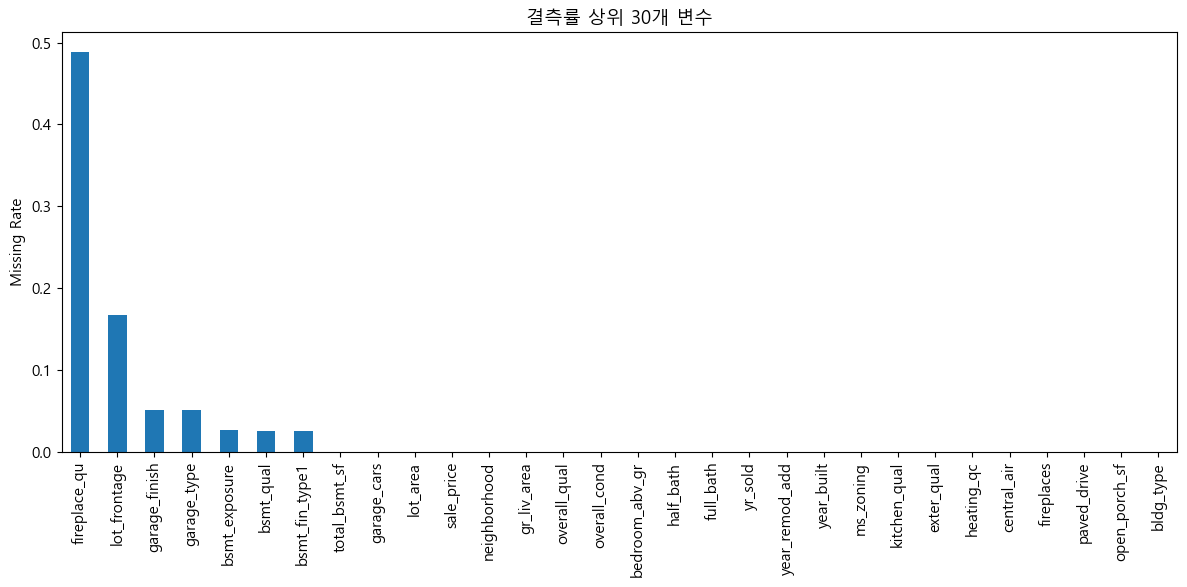


📊 결측률 구간별 변수 개수 집계:
missing_bin
0(Clean)    22
0~40%        8
40~70%       1
70~80%       0
80% 이상       0
Name: count, dtype: int64
💡 해석: 'Fireplace Qu'(49%)와 'Lot Frontage'(17%)를 제외하면 데이터가 전반적으로 깨끗함.


In [10]:
# ==========================================
# 1. 결측치 진단
# ==========================================

# 변수별 결측률, 유니크 개수, dtype 정리 프레임 생성
summary = pd.DataFrame({
    "dtype": df_train.dtypes,
    "n_unique": df_train.nunique(),
    "missing_cnt": df_train.isna().sum(),
})
summary["missing_rate"] = summary["missing_cnt"] / len(df_train)
summary = summary.sort_values("missing_rate", ascending=False)

print("\n📋 [결측률 상위 10개 변수 현황]")
display(summary.head(10))

# 결측률 Barplot
plt.figure(figsize=(12, 6))
summary["missing_rate"].head(30).plot(kind='bar') 
plt.title("결측률 상위 30개 변수")
plt.ylabel("Missing Rate")
plt.tight_layout()
plt.show()

# 결측치 구간별 변수 개수
bins = [0, 0.000001, 0.4, 0.7, 0.8, 1.0]
labels = ["0(Clean)", "0~40%", "40~70%", "70~80%", "80% 이상"]
summary["missing_bin"] = pd.cut(summary["missing_rate"], bins=bins, labels=labels, include_lowest=True)

print("\n📊 결측률 구간별 변수 개수 집계:")
print(summary["missing_bin"].value_counts().sort_index())

# [결과 해석]
print("💡 해석: 'Fireplace Qu'(49%)와 'Lot Frontage'(17%)를 제외하면 데이터가 전반적으로 깨끗함.")


🚨 [IQR 기준 이상치 비율 상위 10개 변수]
overall_cond      0.084
lot_frontage      0.074
open_porch_sf     0.053
lot_area          0.048
sale_price        0.046
total_bsmt_sf     0.040
gr_liv_area       0.025
bedroom_abv_gr    0.025
garage_cars       0.006
fireplaces        0.005
dtype: float64


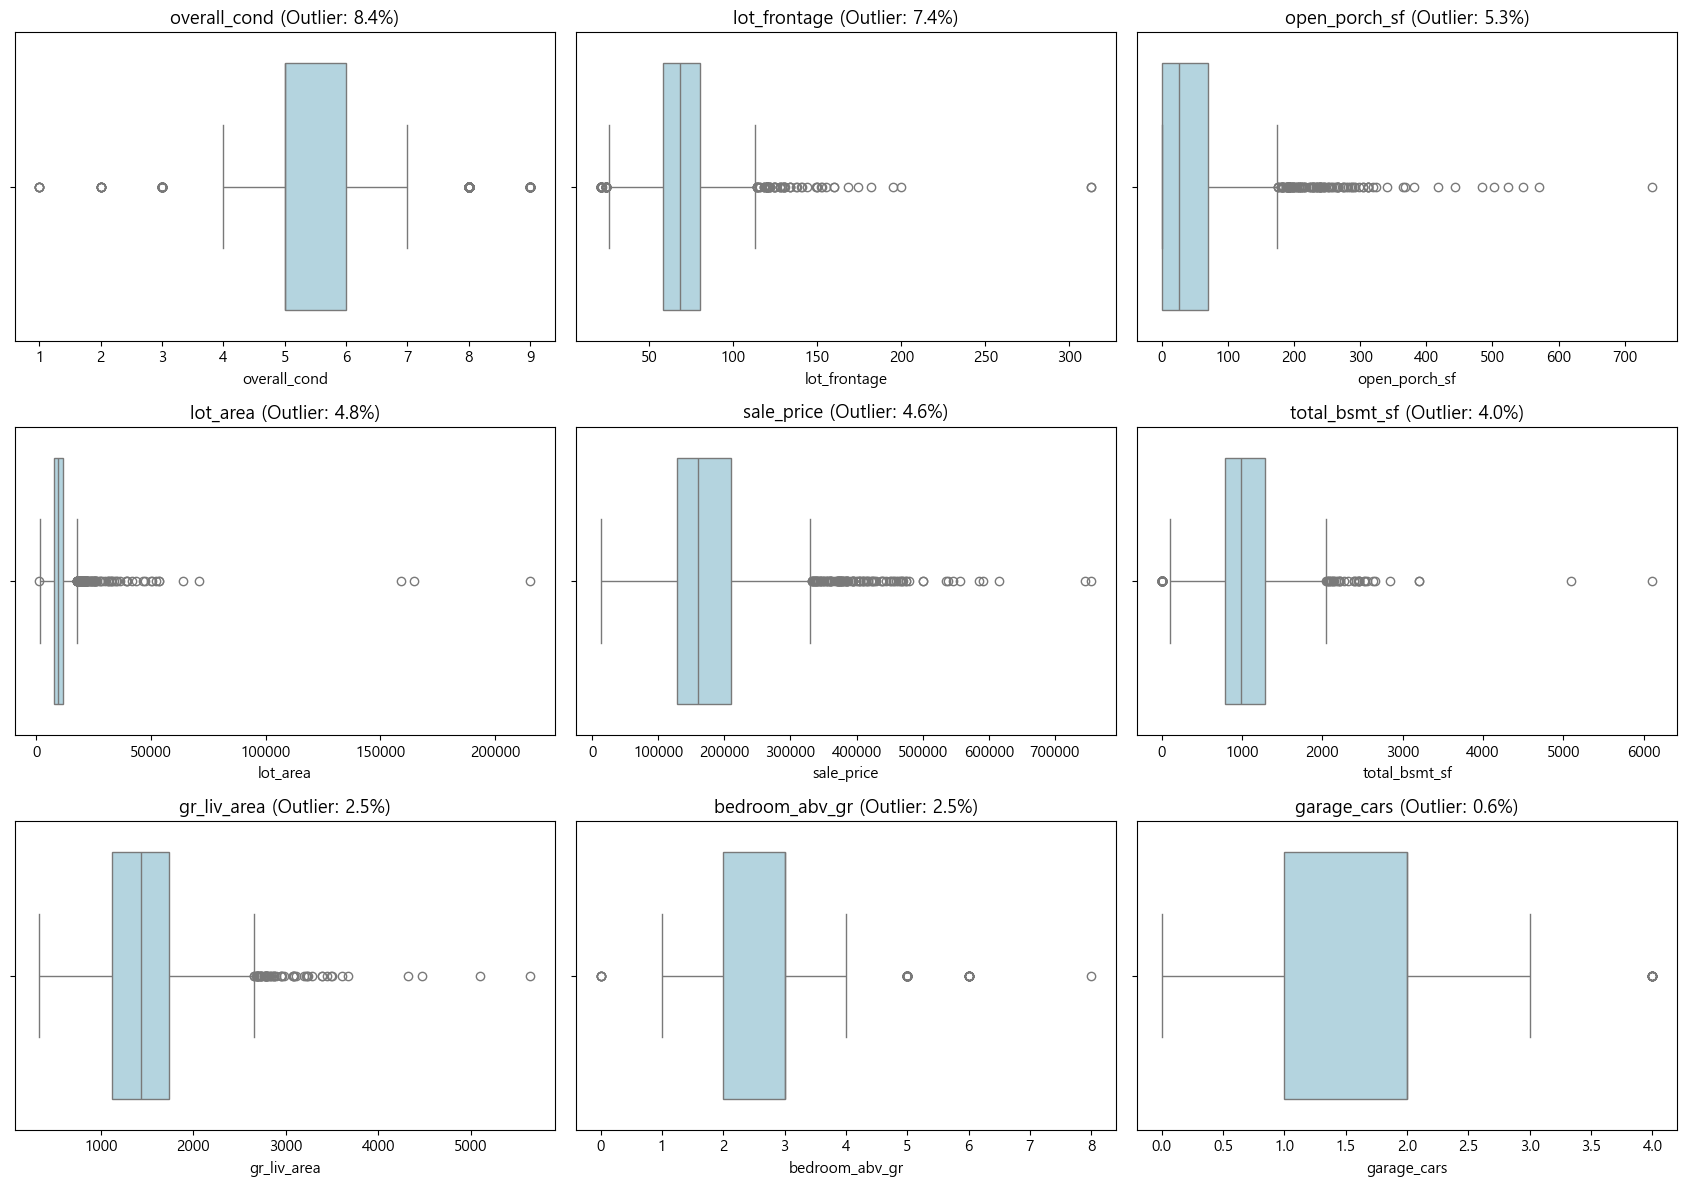

💡 해석: 'Overall Cond'(8%), 'SalePrice'(5%), 'Gr Liv Area'(3%) 등에서 이상치 확인함.
   👉 SalePrice와 Gr Liv Area는 규제 모델로 대응할 예정임.


In [11]:
# ==========================================
# 2 이상치 탐지 (IQR 방식)
# ==========================================
# Note: 이 단계는 분포를 이해하기 위함이며, 값을 바로 삭제하지 않음.

outlier_ratio_simple = {}

# IQR 기반 이상치 비율 계산
for col in num_cols:
    s = df_train[col].dropna()
    q1 = s.quantile(0.25)
    q3 = s.quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    
    # 이상치 비율 저장
    outlier_ratio_simple[col] = ((s < lower) | (s > upper)).mean()

# 결과 정렬
outlier_df_train = pd.Series(outlier_ratio_simple).sort_values(ascending=False)

print("\n🚨 [IQR 기준 이상치 비율 상위 10개 변수]")
print(outlier_df_train.head(10).round(3))

# 이상치 비율 상위 9개 변수 Boxplot
top_outlier_cols = outlier_df_train.head(9).index.tolist()

n = len(top_outlier_cols)
cols = 3
rows = (n + cols - 1) // cols

fig, axes = plt.subplots(rows, cols, figsize=(17, 4 * rows))
axes = axes.flatten()

for i, col in enumerate(top_outlier_cols):
    sns.boxplot(x=df_train[col], ax=axes[i], color='lightblue')
    axes[i].set_title(f"{col} (Outlier: {outlier_df_train[col]*100:.1f}%)")

for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

# [결과 해석]
print("💡 해석: 'Overall Cond'(8%), 'SalePrice'(5%), 'Gr Liv Area'(3%) 등에서 이상치 확인함.")
print("   👉 SalePrice와 Gr Liv Area는 규제 모델로 대응할 예정임.")

------------------------------------------------------------------------------------------------

## 3. 데이터 전처리
- 💡 EDA를 통해 파악한 데이터의 결함(결측, 이상치, 편향)을 해결하고, 모델이 학습하기 최적화된 형태로 가공합니다.
- 💡 Key Point!

    1.  **무결성 확보:** 단순 삭제를 지양하고, 데이터의 특성에 맞게 결측치를 보존하거나 대체

    2.  **분포 보정:** 안정적인 회귀 모델을 위해 타겟 변수의 편향을 완화

    3.  **정보 구조화:** 범주형 변수를 수치화하고, 흩어진 정보를 합쳐 파생 변수 생성
> **과정:** `1. 데이터 정제` $\to$ `2. 데이터 변환` $\to$ `3. 파생 변수 생성`

------------------------------------------------------------------------------------------------

In [12]:
# 타깃 / 피처 분리 (train만!)
y_train = df_train["sale_price"]     # 타깃
X_train = df_train.drop(columns=["sale_price"]) # 피처
# drop -> 데이터 누수 및 과적합 방지

X_test  = df_test.copy()                        # 피처(타깃 없음)
# .copy() -> 원본 훼손 방

# 수치형 / 범주형 컬럼 분리 (train 기준)
num_cols = X_train.select_dtypes(include=['int64', 'float64']).columns.tolist()
cat_cols = X_train.select_dtypes(include=['object']).columns.tolist()

# 1. 모델 학습을 위해 SalePrice를 타깃으로 분리
# 2. 입력 변수는 dtype을 기준으로 수치형과 범주형 피처로 구분
# 3. 이후 인코딩·스케일링·결측치 처리 전략을 적용할 수 있도록 준비


## 3.1 결측치 처리

* **목적:** 결측 발생 원인을 찾고, 각 특성에 맞는 대치법을 적용하여 **데이터의 논리적 정합성** 확보

* **접근:**
    1. **구조적 결측:** '시설 없음'을 의미하는 변수는 **0** 또는 **None**으로 채워 정보 보존
    2. **비구조적 결측:** 실제 유실된 정보는 **중앙값**이나 **동네별 특성**을 활용해 복원
    
### - 상세 내역

1.  **🧱 구조적 결측 처리**

    * **정의:** NaN = **특정 항목이 존재하지 않음**

    * **범주형 변수:** 
        - `Fireplace Qu` ->  "**None**"으로, 모델이 "**벽난로 없는 집**"을 하나의 상태로 학습 가능
        - `Garage` -> "**None**"으로, 원핫 인코딩시 "**garage_type_None**" 같은 더미 생성 및 모델이 "**차고 없는 집**" 구분 가능

        - `BaseMent 관련 변수` -> **NoBasement**로, 결측을 하나의 특성으로 활용
    * **수치형 변수:** 
        - `Garage Cars`, `Total Bsmt Sf` ->  시설이 없으면 면적도 존재할 수 없으므로 **0**으로 대치 
            * 평균값 대치 시 논리적 모순 발생 방지: "**차고/지하실이 있는데 값이 빠진 것처럼**" 왜곡 방지

2.  **🛠️ 비구조적 결측 처리**
    
    * **정의:** NaN = **데이터 누락**

    * **`Lot Frontage`:** 집 자체보다 **동네 도로 특성**에 종속되는 변수는 **Neighborhood별 중앙값**을 사용하여 지역적 특성 왜곡 방지

    * **일반 변수:** 
        * 수치형은 **중앙값**(**.median**), 평균값의 왜곡을 피함 -> 이상치 영향 최소화
        * 범주형은 **최빈값**(**.mode**), 평균을 구할 수 없기에 가장 빈번하게 등장하는 값 선택 -> 통계적 안전성 확보

---
### **🚨 데이터 누수 방지 원칙**
   
   * 💡**미래 데이터(Test)를 보지 않고, 가장 안전한 예측을 하기 위함입니다.**

     * **원칙:** 결측치를 채우는 기준은 오직 **Train 데이터**에서만 구해야함 (Test 통계량 사용 ❌)
     
     * **이유:** Test의 분포를 미리 알고 채우는 것은 '**답안지를 훔쳐보는 컨닝**'과 같아 모델 성능 과대평가 위험

* **적용 프로세스:**
    1. **학습(Fit):** 오직 **Train 데이터**에서만 중앙값/최빈값을 계산

    2. **적용(Transform):** 계산된 'Train의 값'을 **Train과 Test 데이터 양쪽에 동일하게** 대입


#### **💡 Key Point!**

    `"Train 데이터에 포함된 이상치에 의한 통계적 왜곡을 피하고, 가장 보편적인 패턴을 Test 데이터에 안전하게 적용하기 위해 중앙값(수치형)과 최빈값(범주형)을 사용했습니다.`
---

In [13]:
# ==========================================
# 1. 구조적 결측 처리
# ==========================================

for df in [X_train, X_test]:
    # fireplace_qu → 결측 = "None"
    df['fireplace_qu'] = df['fireplace_qu'].fillna("None")
    
    # garage_type / garage_finish → 결측 = "None"
    df['garage_type'] = df['garage_type'].fillna("None")
    df['garage_finish'] = df['garage_finish'].fillna("None")

    # Basement 관련 변수들 → 결측 = "NoBasement"
    basement_cols = ['bsmt_qual', 'bsmt_exposure', 'bsmt_fin_type1']
    for col in basement_cols:
        df[col] = df[col].fillna("NoBasement")

    # garage_cars / total_bsmt_sf → 결측 = "0"
    df['garage_cars'] = df['garage_cars'].fillna(0)
    df['total_bsmt_sf'] = df['total_bsmt_sf'].fillna(0)
    
# [검증]
cols = ['fireplace_qu', 'garage_type', 'garage_finish', 
        'bsmt_qual', 'bsmt_exposure', 'bsmt_fin_type1', 
        'garage_cars', 'total_bsmt_sf']

print("--- 1. 결측치 개수 (모두 0이어야 성공) ---")
print(X_train[cols].isnull().sum())

print("\n--- 2. 채워진 데이터 샘플 확인 ---")
print(X_train[cols].head(5))

--- 1. 결측치 개수 (모두 0이어야 성공) ---
fireplace_qu      0
garage_type       0
garage_finish     0
bsmt_qual         0
bsmt_exposure     0
bsmt_fin_type1    0
garage_cars       0
total_bsmt_sf     0
dtype: int64

--- 2. 채워진 데이터 샘플 확인 ---
  fireplace_qu garage_type garage_finish   bsmt_qual bsmt_exposure  \
0           TA      Attchd           RFn          Gd            No   
1         None      Attchd           Fin          TA            Gd   
2         None     CarPort           Unf  NoBasement    NoBasement   
3         None      Detchd           Unf  NoBasement    NoBasement   
4         None        None          None          Fa            No   

  bsmt_fin_type1  garage_cars  total_bsmt_sf  
0            Unf          2.0         1090.0  
1            LwQ          2.0         1013.0  
2     NoBasement          2.0            0.0  
3     NoBasement          2.0            0.0  
4            Unf          0.0          600.0  


In [14]:
# ==========================================
# 2. 비구조적 결측 처리
# ==========================================

nbhd_median = X_train.groupby('neighborhood')['lot_frontage'].median()

# train / test 둘 다 같은 규칙 적용
# Lot Frontage -> 결측 = "Train 기준 동네별 중앙값"
for df in [X_train, X_test]:
    df['lot_frontage'] = df['lot_frontage'].fillna(
        df['neighborhood'].map(nbhd_median)
    )
    
# 일반 수치형 -> 결측 = "Train 기준 중앙값"
for col in num_cols:
    med = X_train[col].median()
    X_train[col] = X_train[col].fillna(med)
    X_test[col]  = X_test[col].fillna(med)

# 일반 범주형 -> 결측 = "Train 기준 최빈값"
for col in cat_cols:
    mode = X_train[col].mode()[0]
    X_train[col] = X_train[col].fillna(mode)
    X_test[col]  = X_test[col].fillna(mode)

# [검증]
print("--- 1. 결측치 개수 (모두 0이어야 성공) ---")
print(f"lot_frontage 결측 수: {X_train['lot_frontage'].isnull().sum()}")

print(f"X_train 전체 결측 총합: {X_train.isnull().sum().sum()}")
print(f"X_test  전체 결측 총합: {X_test.isnull().sum().sum()}")

print("\n--- 2. 채워진 데이터 샘플 확인 ---")
print(X_train[['neighborhood', 'lot_frontage']].head(5))

--- 1. 결측치 개수 (모두 0이어야 성공) ---
lot_frontage 결측 수: 0
X_train 전체 결측 총합: 0
X_test  전체 결측 총합: 0

--- 2. 채워진 데이터 샘플 확인 ---
  neighborhood  lot_frontage
0       NWAmes          80.0
1      ClearCr          80.5
2        NAmes          70.0
3        NAmes          60.0
4      OldTown          63.0


## 3.2 인코딩 및 스케일링

* **목적:** 데이터의 분포를 교정하고, 문자열 변수를 모델이 학습 가능한 수치형 벡터로 변환하여 **모델의 학습 효율성** 극대화

* **접근:**
    1. **인코딩:** 변수의 성격(순서 유무)에 따라 차별화된 수치화 전략 적용
    2. **분포 교정:** 왜도가 심한 데이터의 정규성을 확보하고 비정상적인 이상치 제거 전략 계획


## -- 범주형 변수 인코딩

### **1. ✂️ 인코딩 전처리**
* **정의:** 인코딩 수행 전, 데이터 분포를 고려하여 범주를 재구성

* **전략:** **희귀 범주 병합**
    * 분포 비율이 **1% 미만**인 극소수 범주, 모델 학습 시 노이즈로 작용하거나 과적합을 유발할 수 있음
    1. ✅ 원핫 인코딩 차원 폭발 방지
    2. ✅ 교차검증 안정화
    3. ✅ 과적합 방지
    4. ✅ 해석 가능성 향상

    -> 💡 **희소 값들을 `Rare`라는 하나의 범주로 통합**하여 모델의 안정성 확보

### **2. 🔢 순서형 변수 인코딩**
* **정의:** 데이터 간에 명확한 서열이나 등급의 높낮이가 존재하는 변수

* **대상:** `Exter Qual`(외관 품질), `Bsmt Exposure`(지하실 노출 수준) ~

* **전략:** **사용자 정의 매핑**
    * 등급의 의미에 맞춰 **가중치 점수**를 부여

    -> 💡 품질이 좋을수록 가격이 높아지는 **양의 상관관계**를 모델이 학습하도록 유도

### **3. 🔠 명목형 변수 인코딩**
* **정의:** 순서나 서열이 없고, 단순한 분류만을 나타내는 변수

* **대상:** `Neighborhood`(이웃), `House Style`(집 스타일) ~

* **전략:** **원-핫 인코딩**
    - 각 범주를 0/1 벡터로 변환하여 서열 정보가 없음을 모델에 전달
    - 구현 코드

        -  pd.get_dummies(drop_first=True): 선형 모델이 학습 가능한 0과 1의 더미 변수로 변환 / `drop_first=True` 유추 가능한 첫 번째 범주 제거

        - align(join='left', axis=1, fill_value=0): Train 데이터의 틀에 맞춰 Test 데이터의 컬럼 구성을 똑같이 맞춤

    -> 💡 변수 간의 완전한 상관관계인 **다중공선성** 및 **Train - Test 차원 불일치**를 사전에 제거

---
> 🛠️ **[Audit 정정]** 위 희귀범주(`Rare`) 병합 코드는 `df_train`/`df_test`만 수정하고, 실제 모델이 쓰는 `X_train`/`X_test`에는 반영되지 않아 **최종 모델에 적용되지 않았다(dead code)**. 따라서 '차원폭발 방지·CV 안정화' 효과는 실측되지 않았다. 수정본 노트북에서는 `OneHotEncoder(min_frequency=0.01)`로 **폴드별 train 기준 자동 처리**하여 동일 의도를 누수 없이 구현했다.

In [15]:
# ==========================================
# 1. 인코딩 전처리
# ==========================================

rare_threshold = 0.01
rare_cols = ["neighborhood"] # 명목형 변수 지정

# 주의: Data Leakage 방지를 위해 기준은 반드시 'Train Set'에서만 산출
for col in rare_cols:
    freq = df_train[col].value_counts(normalize=True)
    rare = freq[freq < rare_threshold].index  # 1% 미만 카테고리 식별
    
    # Train과 Test에 동일한 규칙 적용 ('Rare'로 치환)
    df_train[col] = df_train[col].replace(rare, "Rare")
    df_test[col]  = df_test[col].replace(rare, "Rare")
    
# [검증]
# 1. 병합된 동네 이름 확인
print(f"📉 병합된 1% 미만 희귀 동네 ({len(rare)}개):")
print(list(rare))
print("-" * 30)

# 2. 실제로 'Rare'가 생겼는지 확인 (상위 10개만 출력)
print("✅ [변경 후] Neighborhood 값 분포:")
print(df_train['neighborhood'].value_counts().head(10))

# [결과 해석]
print("\n💡 해석: 'Rare' 카테고리가 새로 생긴 것을 확인할 수 있음.")

📉 병합된 1% 미만 희귀 동네 (7개):
['Blmngtn', 'Veenker', 'NPkVill', 'Blueste', 'Greens', 'GrnHill', 'Landmrk']
------------------------------
✅ [변경 후] Neighborhood 값 분포:
neighborhood
NAmes      367
CollgCr    211
OldTown    199
Edwards    150
Gilbert    138
Somerst    136
NridgHt    121
Sawyer     119
NWAmes     109
SawyerW     98
Name: count, dtype: int64

💡 해석: 'Rare' 카테고리가 새로 생긴 것을 확인할 수 있음.


In [16]:
# ==========================================
# 2. 순서형 변수 인코딩
# ==========================================

# 매핑 규칙 정의 (가중치 부여: 0 ~ 6점)
ordinal_cols = [
    'exter_qual',
    'kitchen_qual',
    'heating_qc',
    'fireplace_qu',
    'bsmt_qual'
]

ordinal_map = {
    "NoBasement": 0,
    "None": 0,
    "Po": 1,
    "Fa": 2,
    "TA": 3,
    "Gd": 4,
    "Ex": 5
}

garage_finish_map = {
    'None': 0,
    'Unf': 1,
    'RFn': 2,
    'Fin': 3
}

bsmtfin1_map = {
    'NoBasement': 0,
    'Unf': 1,
    'LwQ': 2,
    'Rec': 3,
    'BLQ': 4,
    'ALQ': 5,
    'GLQ': 6
}

bsmt_exposure_map = {
    "NoBasement": 0,
    "No": 1,
    "Mn": 2,
    "Av": 3,
    "Gd": 4
}

# 매핑 적용 (Train/Test 반복)
for df in [X_train, X_test]:
    # (1) 품질 관련 변수 일괄 매핑
    for col in ordinal_cols:
        df[col] = df[col].map(ordinal_map)

    # (2) 개별 특성 변수 매핑
    df['garage_finish'] = df['garage_finish'].map(garage_finish_map)
    df['bsmt_fin_type1'] = df['bsmt_fin_type1'].map(bsmtfin1_map)
    df['bsmt_exposure'] = df['bsmt_exposure'].map(bsmt_exposure_map)

# Train과 Test에 동일한 규칙 적용 ('Rare'로 치환)
print(df[['garage_finish','bsmt_fin_type1','bsmt_exposure']])
print(df.loc[:,ordinal_cols])

# [검증]
check_cols = ['exter_qual', 'garage_finish', 'bsmt_fin_type1', 'bsmt_exposure']

print("✅ [변환 확인] 문자열이 숫자로 바뀌었는지 확인 (상위 3행):")
print(X_train[check_cols].head(3))

print("\n✅ [매핑 오류 확인] 변환되지 못한 결측값 개수 (모두 0이어야 성공):")
print(X_train[check_cols].isnull().sum())

# [결과 해석]
print("\n💡 해석: 모든 순서형 변수가 의도한 대로 숫자로 변환된 것을 확인할 수 있음.")

     garage_finish  bsmt_fin_type1  bsmt_exposure
0                1               1              1
1                1               5              1
2                3               1              1
3                0               6              1
4                1               3              1
..             ...             ...            ...
581              3               6              3
582              3               6              4
583              2               1              1
584              1               5              4
585              3               4              1

[586 rows x 3 columns]
     exter_qual  kitchen_qual  heating_qc  fireplace_qu  bsmt_qual
0             3             4           2             4          3
1             3             3           5             0          3
2             4             4           5             4          4
3             3             3           5             0          4
4             3             3           3

In [17]:
# ==========================================
# 3. 명목형 변수 인코딩
# ==========================================

# get_dummies 적용
# drop_first=True로 첫 번째 범주 제거 -> 다중공선성 예방
X_train_ohe = pd.get_dummies(X_train, drop_first=True)
X_test_ohe  = pd.get_dummies(X_test,  drop_first=True)

# 차원 정렬
# Train과 Test의 컬럼 구성을 동일하게 맞춤 (Test에만 있는 범주는 무시, Train에만 있는 범주는 0으로 채움)
X_train_ohe, X_test_ohe = X_train_ohe.align(X_test_ohe, join='left', axis=1, fill_value=0)

print(X_train_ohe)
print(f"\n[인코딩 최종 완료] Train Shape: {X_train_ohe.shape}, Test Shape: {X_test_ohe.shape}")
print("원-핫 인코딩 데이터 샘플:")
print(X_train_ohe.iloc[:3, :5]) # 앞 5개 컬럼만 확인

# [검증]
# 1. 차원(컬럼 개수) 일치 여부 확인
print(f"✅ [차원 동기화 확인] Train 컬럼 수: {X_train_ohe.shape[1]}개 vs Test 컬럼 수: {X_test_ohe.shape[1]}개")
print(f"   -> 일치 여부: {X_train_ohe.shape[1] == X_test_ohe.shape[1]}")
print("-" * 30)

# 2. 실제 데이터 샘플 확인 (0과 1로 변환되었는지)
ohe_sample_cols = [col for col in X_train_ohe.columns if "_" in col][:3] # 변환된 컬럼 3개만 추출
print(f"✅ [변환 샘플] {ohe_sample_cols} ...")
print(X_train_ohe[ohe_sample_cols].head(3))

# [결과 해석]
print("\n💡 해석: Train과 Test의 컬럼 수가 일치하며, 원-핫 인코딩이 정상적으로 수행된 것을 확인할 수 있음.")


      overall_qual  overall_cond  gr_liv_area  lot_area  lot_frontage  \
0                7             5         1370     10400          80.0   
1                5             5         2126     28698          80.5   
2                4             5         1224      9842          70.0   
3                4             5         1040      7200          60.0   
4                4             6         1701      7627          63.0   
...            ...           ...          ...       ...           ...   
2339             5             5         1424     41600         195.0   
2340             7             5         1414      7750          63.0   
2341             6             5         1728      8791          64.0   
2342             5             5         1740      7308          81.0   
2343             5             8          768      7200          60.0   

      total_bsmt_sf  year_built  year_remod_add  yr_sold  full_bath  ...  \
0            1090.0        1976            1976

## -- 분포 교정

* **목적:** 인위적인 삭제(Winsorization) 없이, **데이터를 최대한 보존하되 이상치의 영향력만 완화**하여 모델의 일반화 성능 확보

* **접근:**
    1.  **규제 모델 도입 계획:** 페널티를 활용해 이상치 민감도 억제
    2.  **표준화 및 교차검증:** 변수 간 스케일을 맞추고 교차 검증을 통해 특정 극단값에 대한 과적합 방지

### - 대응 전략 상세 내역

#### **1. ⛓️ 규제 모델 도입 계획** (코드 실현X)
* **정의:** 선형 모델에 페널티를 부과하여 회귀 계수의 크기를 강제로 제어하는 모델링 기법

* **구현:** **Lasso**,**Ridge**, **Elsastic** 회귀 모델 고려

* **효과:** 💡 모델 학습 시 **가중치에 규제를 가함**으로써, 이상치 데이터에 의해 회귀선이 과도하게 휘둘리는 **민감도 억제**

#### **2. 📐 표준화**
* **정의:** 서로 다른 단위를 가진 변수들의 스케일을 통일하여 모델이 특정 변수에 편향되지 않도록 조정

* **구현:** `StandardScaler`를 적용하여 모든 변수의 분포를 **평균 0, 표준편차 1**인 표준정규분포 형태로 변환
    - **scaler.**
        - fit_transform(Train) / transform(Test)

* **효과:** 💡 스케일이 큰 변수가 모델의 **가중치 학습을 지배 방지** 및 Ridge, Lasso 등 **규제 기반 모델의 성능**과 수렴 속도 향상

#### **3. 🔄 교차 검증**
* **정의:** 전체 데이터를 여러 개의 폴드로 나누어 학습과 검증을 반복함으로써, 특정 데이터셋에 과적합되는 것을 막고 모델의 **일반화 성능** 평가

* **구현:**
    - **KFold(n_splits, shuffle, random_state)**
        - `n_splits=5`: 5등분하여 검증셋으로 활용, `shuffle=True`: 데이터의 순서에 의한 편향을 막기 위해 섞음

* **효과:** 💡 단일 검증셋(Hold-out) 사용 시 발생할 수 있는 **우연성을 배제**하고, 새로운 데이터에 대해서도 **안정적인 예측 성능** 보장

In [18]:
# ==========================================
# 2. 표준화
# ==========================================

# 수치형 컬럼만 선택 (One-Hot Encoding된 데이터 기준)
num_cols = X_train.select_dtypes(include=['int64', 'float64']).columns

# 스케일러 적용 (Train 기준)
scaler = StandardScaler()
X_train_ohe[num_cols] = scaler.fit_transform(X_train_ohe[num_cols])
X_test_ohe[num_cols]  = scaler.transform(X_test_ohe[num_cols])

# [검증]
print("\n[표준화 결과 검증]")

# 평균(0)과 표준편차(1) 확인
# nanmean, nanstd를 써서 에러나 NaN을 무시하고 계산합니다.
avg = np.nanmean(X_train_ohe[num_cols].values)
std = np.nanstd(X_train_ohe[num_cols].values)

print(f"\n변환 결과: 평균 {avg:.0f}, 표준편차 {std:.0f}")
print("   (평균 0, 표준편차 1이면 성공)")

# [결과 해석]
print("\n💡 해석: 수치형 변수들이 평균 0, 표준편차 1을 따름")


[표준화 결과 검증]

변환 결과: 평균 -0, 표준편차 1
   (평균 0, 표준편차 1이면 성공)

💡 해석: 수치형 변수들이 평균 0, 표준편차 1을 따름


In [19]:
# ==========================================
# 3. 교차 검증
# ==========================================

# 데이터를 무작위로 섞어(shuffle) 순서 편향을 방지하고, 5등분(n_splits=5)하여 일반화 성능을 검증함
cv = KFold(n_splits=5, shuffle=True, random_state=42)

# [검증] 설정값 출력
print(f" 교차 검증 설정 확인: {cv}")
print(f"   - n_splits: {cv.get_n_splits(X_train)}개")
print(f"   - shuffle: {cv.shuffle}")
print(f"   - random_state: {cv.random_state}")
print("   💡 해석: 데이터를 무작위로 섞은 뒤 5등분하여 검증")


 교차 검증 설정 확인: KFold(n_splits=5, random_state=42, shuffle=True)
   - n_splits: 5개
   - shuffle: True
   - random_state: 42
   💡 해석: 데이터를 무작위로 섞은 뒤 5등분하여 검증


## 3.3 파생 변수 생성
* **목적:** 과적합 방지를 위해 **최소한의 파생 변수**만 생성

* **전략:** 도메인 지식에 기반하여 **설명력이 높고 안정적인 변수**만 엄선하여 채택

* **주요 생성 변수:**
    1.  **🌐 `Total SF` (실질적 전체 면적)**
        * **수식:** `Total Bsmt SF` (지하) + `Gr Liv Area` (지상)

        * **배경:** 지하와 지상 면적이 분리되어 있어, 집의 **전체 규모**를 반영하지 못함

        * **의의:** 두 변수를 합쳐 다중공선성을 줄이고 모델의 설명력을 강화함

    2.  **⏳ `House Age` (건물 노후도)**
        * **수식:** `Yr Sold` (판매 연도) - `Year Built` (건축 연도)

        * **배경:** 단순히 '언제 지어졌는가'보다 **판매 시점에서 얼마나 낡았는가**가 가격 감가상각에 큰 영향을 미침

        * **의의:** 건물의 노후화를 반영해 모델의 설명력을 강화함

In [20]:
# ==========================================
# 파생 변수 생성
# ==========================================

for df in [X_train, X_test]:
    # (1) 총 면적: 지상 + 지하
    df['total_sf'] = df['total_bsmt_sf'] + df['gr_liv_area']
    
    # (2) 집 나이: 팔린 연도 - 지어진 연도
    df['house_age'] = df['yr_sold'] - df['year_built']

print(df[['total_sf','house_age']])

     total_sf  house_age
0      2254.0         83
1      1524.0         34
2      2520.0          3
3      1980.0         13
4      1813.0         82
..        ...        ...
581    2014.0          4
582    4984.0          5
583    2810.0          6
584    1872.0         40
585    2512.0         43

[586 rows x 2 columns]


## 4. 모델링 및 성능 평가
`- 💡 단순히 성능이 좋은 모델을 찾는 것을 넘어, 왜 그 모델이 이 데이터에 적합한지를 여러 번의 테스트를 통해 증명했습니다.`

### 🧪 4.1 모델링 실험 설계
* **비교 대상:** 
    1.  **Ridge:** L2 규제로 변수의 영향력을 골고루 분산
    2.  **Lasso:** L1 규제로 불필요한 변수를 제거
    3.  **ElasticNet:** L1과 L2의 장점을 결합하여 균형 잡힌 규제 적용
    4.  **✔️ 이원화 모델링 전략: Lasso로 중요 변수를 먼저 선별하고, Ridge로 최종 예측하는 단계별 접근**

* **평가 지표:** **RMSE**
    * 오차를 제곱하여 큰 오차에 대해 더 높은 패널티를 부여
        - 주택 가격 예측 모델이 특정 데이터에서 **극단적으로 틀리는 현상을 방지**하고, 전체적으로 안정적인 성능을 확보하기 위함

### 📊 4.2 실험 결과 요약

| 순위 | 모델 | 검증 점수 (CV RMSE) | 비고 |
| :--- | :--- | :--- | :--- |
| **1** | **ElasticNet** | **30,129** | **🏆 최종 모델 선정** |
| 2 | Ridge | 30,149 | 근소한 차이로 2위 |
| 3 | Lasso | 30,291 | - |
| 4 | Lasso 선택 + Ridge | 43,540 | ⚠️ 성능 저하 (과소적합) |

> ⚠️ **정정:** 1~3위의 점수 차이(20~160)는 fold 표준편차(±약 7,300)보다 훨씬 작아 **순위 자체가 통계적으로 무의미**하다. '🏆 최종 모델 선정'은 성능 1위가 아니라 **동등성 하의 선택**으로 읽어야 한다.

## **🏆 4.3 최종 모델 선정: ElasticNet**

### **1. ✨ 선정 이유: 이중 규제를 통한 모델의 견고성 확보**

> 💡 [Key Takeaway!]      **ElasticNet**은 L1(변수 선택)과 L2(다중공선성 제어)의 **이중 규제**를 통해 **데이터의 이상치** 및 **변수 간 강한 공선성 문제를 해결**하여 최적의 모델 견고성과 예측 성능을 달성함

* **이상치/잡음 변수 제어:** L1 규제 -> 튀는 값에 민감한 변수의 가중치를 억제하거나 0으로 만들어 변수의 영향력을 축소
* **다중공선성 제어:** L2 규제 -> 강한 상관관계를 가진 변수들의 가중치를 분산시켜 모델의 과적합을 방지

-> **결론(정정):** 세 규제 모델(Ridge·Lasso·ElasticNet)의 CV RMSE 차이는 fold 표준편차(±약 7,300)의 1% 미만으로 **통계적으로 동등**하다. ElasticNet은 성능 우위가 아니라 **단순성·계수 안정성**을 근거로 대표 모델로 채택했다.

### **2. ⚖️ 하이퍼파라미터 해석**
* **Best Params:** `{'alpha': 0.03, 'l1_ratio': 0.9}`
* **해석:** `l1_ratio`가 0.9라는 것은 Lasso(변수 선택)의 성향을 90%, Ridge(안정성)의 성향을 10% 섞었다는 의미

-> **결론:** 불필요한 변수는 과감히 쳐내되(Lasso), 최소한의 안정장치(Ridge)를 남겨둔 구성이 이 데이터에 최적임을 발견


### ⚠️ 4.4 실패 사례 분석
**"Lasso 선택 $\to$ Ridge 예측" 파이프라인은 왜 실패했는가?**
* **결과:** RMSE가 43,540으로 단일 모델보다 훨씬 나쁜 성능을 기록

* **원인 분석:**
    * Lasso가 변수를 선택하는 과정(`SelectFromModel`)에서 기준(`threshold='mean'`)이 너무 엄격
    * **정보 손실로 인한 과소적합**: 전체 74개 변수 중 단 **21개**만 남겼는데, 이때 집값 예측에 필요한 세부 정보까지 과하게 손실됨

* **교훈:** 무조건 변수를 줄이는 것이 좋은 게 아니며, ElasticNet처럼 **모든 변수를 가져가되 가중치만 조절하는 방식**이 이번 데이터에는 더 효과적

---
> 🛠️ **[Audit 정정 요약]** ① 모델 순위는 fold 표준편차 대비 무의미(동등). ② '🏆'은 성능 1위가 아닌 단순성 기반 선택. ③ Lasso→Ridge '실패담'은 `threshold='mean'`이라는 단일·비통제 기준의 결과이므로 일반화된 교훈으로 과대해석하지 않는다.

In [21]:
# ==========================================
# Elastic Net
# ==========================================

# 변수명 재설정 (원본 데이터 오염 방지를 위해 깊은 복사 사용)
X_train = X_train_ohe.copy()
X_test  = X_test_ohe.copy()

# 모델 초기화
enet = ElasticNet(max_iter=50000, random_state=42) 
# - max_iter: 최적화 반복 횟수
# - random_state: 결과 재현성을 위해 고정

# 튜닝할 하이퍼파라미터 그리드 설정
param_grid_enet = {
    'alpha': [
        0.0001, 0.0003,
        0.001,  0.003,
        0.01,   0.03,
        0.1,    0.3,
        1.0
    ],
    'l1_ratio': [0.05, 0.1, 0.3, 0.5, 0.7, 0.9]
    
}
# - alpha: 규제 강도 (클수록 계수 shrink ↑, 과적합 ↓, 과소적합 위험 ↑)
# - l1_ratio:
#     0에 가까울수록 Ridge(L2) 성향,
#     1에 가까울수록 Lasso(L1) 성향,
#     중간값은 두 규제를 적절히 혼합한 Elastic Net 영역

# 공통 교차검증 전략(5-Fold CV)
cv = KFold(n_splits=5, shuffle=True, random_state=42)

# GridSearchCV로 최적(alpha, l1_ratio) 탐색
grid_enet = GridSearchCV(  #GridSearchCV는 하이퍼파라미터 튜닝을 자동화하는 도구
    estimator=enet,
    param_grid=param_grid_enet,
    scoring='neg_root_mean_squared_error',
    # RMSE를 기준으로 평가.
    # 사이킷런은 '큰 점수'를 좋게 평가하므로, RMSE(작을수록 좋음)에 음수(-)를 붙여 사용함.
    cv=cv,
    n_jobs=-1
)

# 실제 학습 + 교차검증 + 하이퍼파라미터 탐색
grid_enet.fit(X_train, y_train)

print("Best params:", grid_enet.best_params_)
print("Best CV RMSE:", -grid_enet.best_score_)

Best params: {'alpha': 0.03, 'l1_ratio': 0.9}
Best CV RMSE: 30129.947146290633


## 5. 모델 평가 및 해석

### 📊 5.1 정량적 평가

* **Best CV RMSE:** **30129.95** (ElasticNet, 최적의 `alpha`와 `l1_ratio` 조합)
* **Train vs Test Gap:** 학습 데이터와 테스트 데이터의 성능 차이를 확인하여 **과적합 여부**를 최종 진단(두 점수 차이가 크지 않음을 확인)

### 🤔 5.2 정성적 해석

모델이 학습한 가중치를 분석하여 주택 가격 결정 요인을 해석

* **📈 가격 상승 요인:**
    * 실제 계수(coefficient) 분석 결과 가격 상승 1순위 요인은 **입지(Neighborhood: StoneBr·NridgHt 등)와 건물 유형(Bldg Type)**, 이어 **지상 면적(Gr Liv Area)·전반 품질(Overall Qual)** 순이었다 $\to$ '어디에 있는가(입지)'의 설명력이 '얼마나 큰가(면적)'보다 컸다. *(주의: 파생변수 `Total SF`는 감사에서 최종 모델에 누락돼 있었음을 발견·수정함 — 수정본 노트북 §6 참조)*
* **📉 가격 하락 요인:**
    * **House Age (노후도)** $\to$ 건물이 오래될수록 가격이 하락하는 **감가상각 경향**이 모델에 명확하게 반영됨

## 6. 결론

### 📚 6.1 프로젝트 요약
* 본 프로젝트는 Ames Housing 데이터를 활용하여 **RMSE 30,129** 수준의 가격 예측 모델을 구축했습니다.
* Private Test 기준 **M 0.8708(전체 2위), Train–Test Gap 1.0%**로 안정적인 일반화 성능을 확인했습니다. 규제 선형모델 + 보수적 전처리(이상치 삭제 대신 규제로 흡수)가 과적합 억제에 기여한 것으로 보이며, 세 규제 모델의 성능은 통계적으로 동등했습니다.

### ✅ 6.2 기술적 기여 및 의사결정 회고

최종 결과는 과정에서 내린 핵심적인 기술적 의사결정의 결과

| 구분 | 주요 의사결정 (What & How) | 논리적 근거 (Why) |
| :--- | :--- | :--- |
| **최종 모델** | **ElasticNet** 채택 및 이중 규제 전략 | **L1/L2 규제**를 동시에 적용하여 데이터의 **이상치**와 **다중공선성** 문제를 한번에 해결, 모델의 견고성 확보 |
| **평가 지표** | **RMSE** 채택 | 오차를 제곱하여 계산함으로써 **큰 오차**에 가중치를 부여하여, 모델이 안정적인 예측을 하도록 유도 |
| **전처리** | **`align()` 함수** 사용 | 원-핫 인코딩 후 Train/Test 데이터셋 간의 **열(Column) 불일치**를 방지하고, 모델 학습의 일관성 확보 |

---
> 🛠️ **[Audit 정정]** §5.2의 변수중요도는 원본 노트북에 **산출 코드가 없었다.** 위 정정 문장의 계수 순위는 누수를 제거한 수정본 노트북(`notebooks/01_final_model_corrected.ipynb` §6)에서 실제 추출한 값이다. 또한 §5.1 'Train vs Test Gap'은 라벨 없는 Private셋으로는 산출 불가했으나, **대회 리더보드 기준 실제 Gap은 1.0%**로 과적합 징후가 거의 없음이 외부 검증되었다.

# 데이터 저장 및 재현성 확인

In [22]:
# ==========================================
# 📦 7) 최종 모델 추출 & 예측값 생성
# ==========================================
import numpy as np
import pandas as pd
import joblib

# 1) GridSearchCV에서 최적 ElasticNet 모델 꺼내기
best_model = grid_enet.best_estimator_
print("✅ 최종 모델(best_model):", best_model)

# 2) Train / Test 예측 (로그 스케일 → 원 스케일 복구)

# (1) Train 예측
y_pred_train = best_model.predict(X_train)     # 로그 스케일

# (2) Test 예측
y_pred_test = best_model.predict(X_test)      # 로그 스케일

print("Train 예측 개수:", len(y_pred_train))
print("Test 예측 개수:", len(y_pred_test))


✅ 최종 모델(best_model): ElasticNet(alpha=0.03, l1_ratio=0.9, max_iter=50000, random_state=42)
Train 예측 개수: 2344
Test 예측 개수: 586


In [23]:
# ==========================================
# 📄 8) submission_train.csv 생성
# ==========================================

# 1) 전처리된 feature 복사
df_sub_train = X_train.copy()

# 2) y_true, y_pred 추가 (둘 다 원 스케일)
df_sub_train["y_true"] = df_train["sale_price"].values
df_sub_train["y_pred"] = y_pred_train

# 3) 컬럼 순서 정리: [feature들] + [y_true] + [y_pred]
feature_cols = X_train.columns.tolist()
df_sub_train = df_sub_train[feature_cols + ["y_true", "y_pred"]]

# 4) 저장
# df_sub_train[["y_true", "y_pred"]] = df_sub_train[["y_true", "y_pred"]].round(10)
df_sub_train.to_csv("submission_train.csv", index=False,float_format="%.17f")
print("✅ submission_train.csv 저장 완료,", "shape:", df_sub_train.shape)


✅ submission_train.csv 저장 완료, shape: (2344, 76)


In [24]:
# ==========================================
# 📄 9) submission_test.csv 생성
# ==========================================

df_sub_test = X_test.copy()
df_sub_test["y_pred"] = y_pred_test   # 원 스케일 예측값

# Train과 feature 순서를 정확히 맞추기 위해 X_train 기준으로 정렬
feature_cols_test = X_train.columns.tolist()
df_sub_test = df_sub_test[feature_cols_test + ["y_pred"]]

# df_sub_test["y_pred"]=df_sub_test["y_pred"].round(10)
df_sub_test.to_csv("submission_test.csv", index=False,float_format="%.17f")
print("✅ submission_test.csv 저장 완료,", "shape:", df_sub_test.shape)


✅ submission_test.csv 저장 완료, shape: (586, 75)


In [25]:
# ==========================================
# 💾 10) 최종 모델 객체 저장 (model.pkl)
# ==========================================

joblib.dump(best_model, "model.pkl")
print("✅ model.pkl 저장 완료")


✅ model.pkl 저장 완료


In [26]:
import pandas as pd
import joblib

# 1. 길이 확인
df_train_pub = pd.read_csv('regression_train_public.csv')  # 회귀: regression_train_public.csv
df_sub_train = pd.read_csv('submission_train.csv')
df_sub_test = pd.read_csv('submission_test.csv')

print(f"Train 원본: {len(df_train_pub)}, 제출: {len(df_sub_train)}")  # 같아야 함
# Test 길이는 제공된 test_private.csv와 비교

# 2. 재현성 확인 (Test)
model = joblib.load('model.pkl')
X_test = df_sub_test.drop(columns=['y_pred'])
y_pred_saved = df_sub_test['y_pred']
y_pred_reload = model.predict(X_test)

print(f"예측 일치: {(y_pred_saved.round(2) == y_pred_reload.round(2)).all()}")  # True여야 함

# 3. 재현성 확인 (Train)
X_train = df_sub_train.drop(columns=['y_true', 'y_pred'])
y_pred_train_saved = df_sub_train['y_pred']
y_pred_train_reload = model.predict(X_train)

print(f"Train 예측 일치: {(y_pred_train_saved.round(2) == y_pred_train_reload.round(2)).all()}")  # True여야 함

Train 원본: 2344, 제출: 2344
예측 일치: True
Train 예측 일치: True


## 후보 모델 검증 결과

In [27]:
# ===============================
# 📌 Ridge 모델 + GridSearchCV
# ===============================
ridge = Ridge(random_state=42)

param_grid_ridge = {
    'alpha': [0.01, 0.03, 0.1, 0.3, 1, 3, 10, 30]
}

grid_ridge = GridSearchCV(
    estimator=ridge,
    param_grid=param_grid_ridge,
    scoring='neg_root_mean_squared_error',  # RMSE 기준
    cv=cv,
    n_jobs=-1,
    verbose=1
)

grid_ridge.fit(X_train, y_train)

print("\n🔹 [Ridge CV 결과]")
print("Best params (Ridge):", grid_ridge.best_params_)
print("Best CV RMSE (log 스케일):", -grid_ridge.best_score_)

Fitting 5 folds for each of 8 candidates, totalling 40 fits

🔹 [Ridge CV 결과]
Best params (Ridge): {'alpha': 10}
Best CV RMSE (log 스케일): 30149.879867195104


In [28]:
# ===============================
# 📌 Lasso 모델 + GridSearchCV
# ===============================
lasso = Lasso(max_iter=50000, random_state=42)

param_grid_lasso = {
    'alpha': [0.0001, 0.0003, 0.001, 0.003, 0.01, 0.03, 0.1]
}

grid_lasso = GridSearchCV(
    estimator=lasso,
    param_grid=param_grid_lasso,
    scoring='neg_root_mean_squared_error',
    cv=cv,
    n_jobs=-1,
    verbose=1
)

grid_lasso.fit(X_train, y_train)

print("\n🔹 [Lasso CV 결과]")
print("Best params (Lasso):", grid_lasso.best_params_)
print("Best CV RMSE (log 스케일):", -grid_lasso.best_score_)

Fitting 5 folds for each of 7 candidates, totalling 35 fits

🔹 [Lasso CV 결과]
Best params (Lasso): {'alpha': 0.1}
Best CV RMSE (log 스케일): 30291.309906383733


In [29]:
from sklearn.feature_selection import SelectFromModel
best_lasso = grid_lasso.best_estimator_

# ==========================================
# 📌 (1) Lasso로 변수 선택
# ==========================================
# 위에서 구한 best_lasso 사용
selector = SelectFromModel(
    estimator=best_lasso,   # 이미 학습된 Lasso
    prefit=True,
    threshold='mean'        # 중요도(계수 절댓값)의 평균 이상만 선택
)

X_train_sel = selector.transform(X_train)
X_test_sel  = selector.transform(X_test)

print("\n선택된 변수 개수:", X_train_sel.shape[1], "/", X_train.shape[1])

# ==========================================
# 📌 (2) 선택된 변수만 가지고 Ridge 그리드서치
# ==========================================
ridge_fs = Ridge(random_state=42)

param_grid_ridge_fs = {
    'alpha': [0.01, 0.03, 0.1, 0.3, 1, 3, 10, 30]
}

grid_ridge_fs = GridSearchCV(
    estimator=ridge_fs,
    param_grid=param_grid_ridge_fs,
    scoring='neg_root_mean_squared_error',
    cv=cv,
    n_jobs=-1,
    verbose=1
)

grid_ridge_fs.fit(X_train_sel, y_train)

print("\n🔹 [Lasso 선택 변수 + Ridge CV 결과]")
print("Best params (Lasso+Ridge):", grid_ridge_fs.best_params_)
print("Best CV RMSE :", -grid_ridge_fs.best_score_)


선택된 변수 개수: 21 / 74
Fitting 5 folds for each of 8 candidates, totalling 40 fits

🔹 [Lasso 선택 변수 + Ridge CV 결과]
Best params (Lasso+Ridge): {'alpha': 1}
Best CV RMSE : 43540.34344621941


c:\projects\data_mine25\.venv\Lib\site-packages\sklearn\utils\validation.py:2742: UserWarning: X has feature names, but SelectFromModel was fitted without feature names
  warnings.warn(
c:\projects\data_mine25\.venv\Lib\site-packages\sklearn\utils\validation.py:2742: UserWarning: X has feature names, but SelectFromModel was fitted without feature names
  warnings.warn(



---
# 부록
---

# 📌 범주형 변수 사전 EDA

- 구조적 특징(**범주 수·희귀 범주·타깃과의 관계**)을 파악해 인코딩 전략(**OHE/순서형/rare 통합**) 및 전처리 설계를 결정하기 위한 사전 EDA 과정


## -- 범주형 변수 EDA

* 의도: 범주 수가 많은 변수 확인 및 희귀 카테고리(<1%) 탐색

* 목적:
  1. 원-핫 인코딩 적용 시 발생할 수 있는 컬럼 수 폭발 가능성 사전 확인
  2. rare category 병합 여부 판단
  3. 전체 전처리 설계의 단순화와 안정성 확보

💡 위 목적을 충족하기 위한 범주형 변수 EDA 절차를 수행함


In [30]:
# ============================================
# 범주형 변수 EDA (희귀 카테고리 / 범주 수 많은 변수 찾기)
# ============================================
cat_cardinality = df_train[cat_cols].nunique().sort_values(ascending=False)
print("\n🔡 범주 수가 많은 범주형 변수 TOP 15:")
print(cat_cardinality.head(10))

# 범주 수가 10개 초과인 변수 목록 (원핫 vs 기타 인코딩 논의용)
high_card_cols = cat_cardinality[cat_cardinality > 10].index.tolist()
print("\n 범주 수 > 10인 변수들:")
print(high_card_cols)

# Note: 아래 희귀 카테고리 계산은 전체 데이터 비율 기준으로 한 'EDA 참고용'
# 실제 rare category 처리는 OneHotEncoder(min_frequency=0.01)가
# CV의 train fold 기준으로 자동 처리함.

# 각 범주형 변수에서 희귀 카테고리 후보 (비율 < 1%인 범주 수)
rare_info = {}
threshold = 0.01  # 1%
for col in cat_cols:
    vc = df_train[col].value_counts(normalize=True, dropna=True)
    rare_cnt = (vc < threshold).sum()
    rare_info[col] = {
        "n_unique": vc.shape[0],
        "n_rare(<1%)": rare_cnt
    }

rare_df_train = pd.DataFrame(rare_info).T.sort_values("n_rare(<1%)", ascending=False)
print("\n🌱 희귀 카테고리(비율 < 1%) 많은 변수 TOP 10:")
print(rare_df_train.head(10))



🔡 범주 수가 많은 범주형 변수 TOP 15:
neighborhood      22
ms_zoning          7
garage_type        6
sale_condition     6
bsmt_fin_type1     6
bsmt_qual          5
fireplace_qu       5
bldg_type          5
heating_qc         5
kitchen_qual       4
dtype: int64

 범주 수 > 10인 변수들:
['neighborhood']

🌱 희귀 카테고리(비율 < 1%) 많은 변수 TOP 10:
                n_unique  n_rare(<1%)
ms_zoning              7            3
garage_type            6            2
sale_condition         6            2
heating_qc             5            1
bsmt_qual              5            1
kitchen_qual           4            0
neighborhood          22            0
bsmt_exposure          4            0
garage_finish          3            0
exter_qual             4            0


## -- 범주형 변수 vs 타겟 관계 분석

**목적:** 범주형 변수에 따른 타겟(SalePrice) 분포 차이를 시각화하여 **변수의 영향력**을 파악하고, 최적의 **인코딩 전략** 수립

* **접근:** `Boxplot`을 통해 범주별 중앙값의 차이와 데이터 분포의 퍼짐 정도를 직관적으로 비교

**주요 점검 포인트:**

1.  **순서성 검증** (예: `KitchenQual`)
    * **관점:** 등급(Po < ... < Ex)이 높아질수록 가격의 중앙값도 비례해서 상승하는가?
    * **전략:** 뚜렷한 상승 경향이 보인다면 **순서형 인코딩(Ordinal Encoding)** 적용의 강력한 근거 확보

2.  **집단 간 변별력 확인** (예: `Neighborhood`)
    * **관점:** 특정 범주(지역) 간에 가격대가 뚜렷하게 구분(고가/중가/저가)되는가?
    * **전략:** 가격 분포가 유사한 범주끼리 묶거나, 관측치가 적은 **희귀 카테고리**를 통합하여 모델 안정성 확보

3.  **결론 도출:**
    * 단순 원-핫 인코딩을 할지, 순서를 살릴지, 혹은 범주를 재그룹화할지 결정

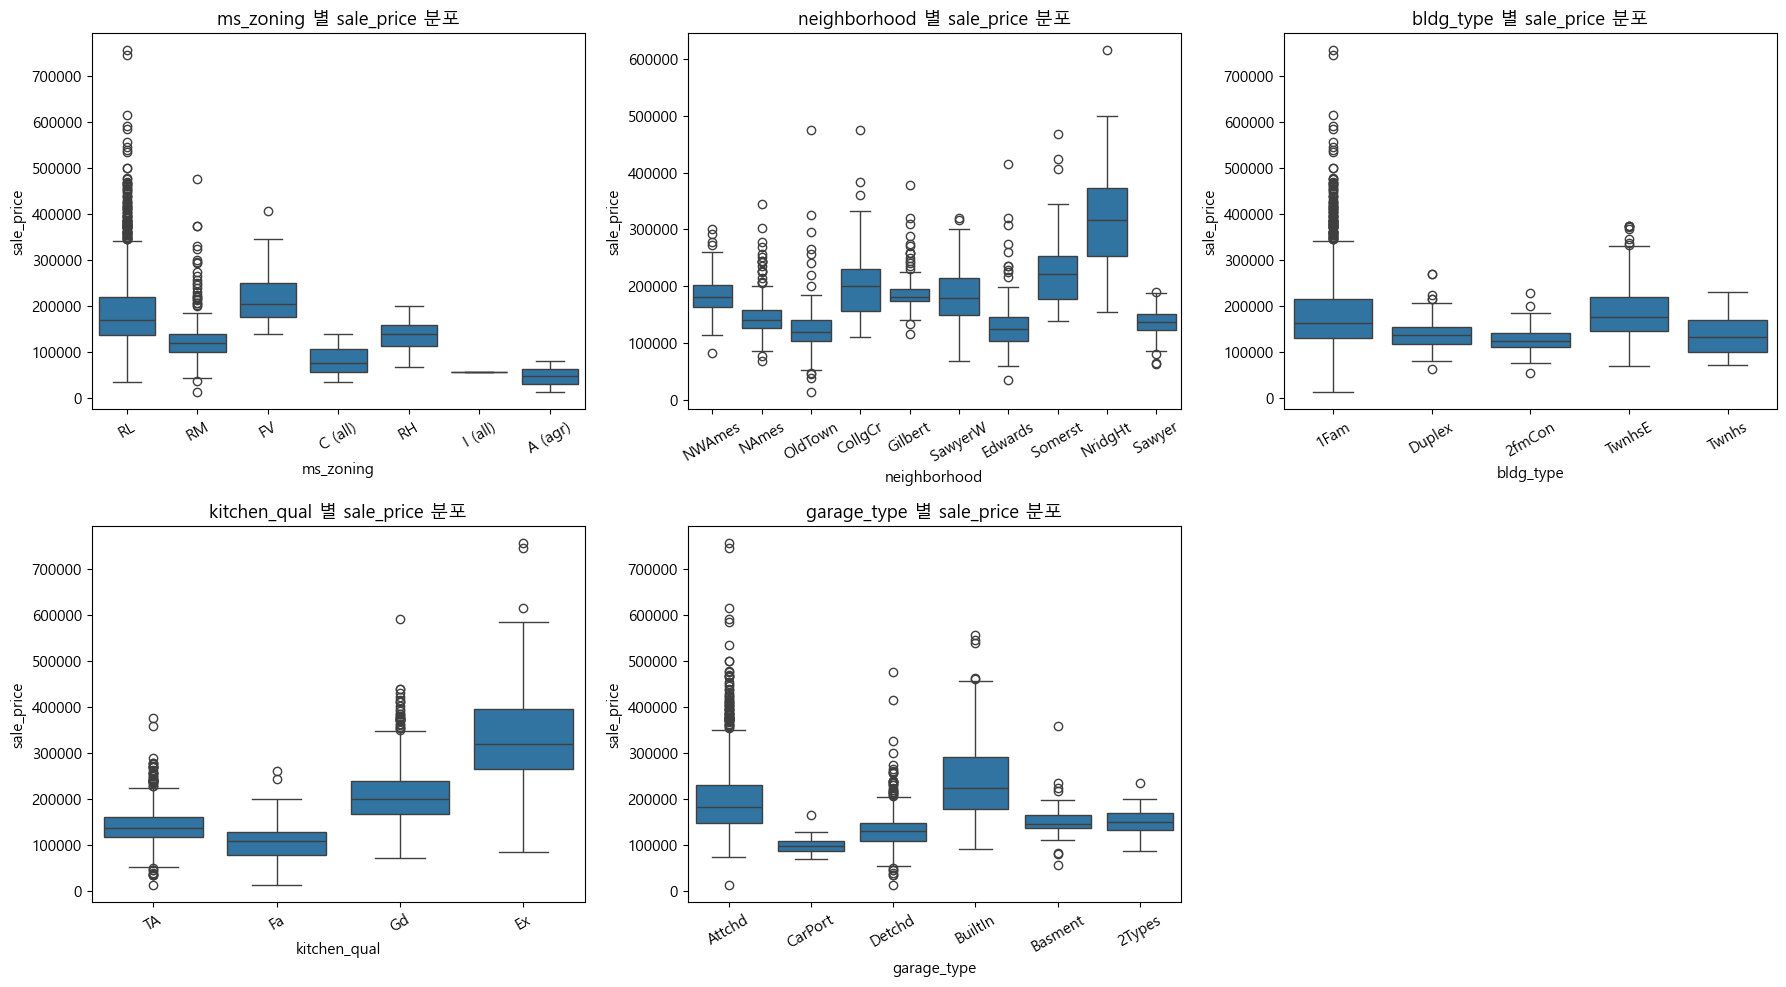

In [31]:
# ============================================
# 범주형 vs 타깃 관계
# ============================================
target_col = "sale_price" 

cat_for_box = ["ms_zoning", "neighborhood", "bldg_type", "kitchen_qual", "garage_type"]

n = len(cat_for_box)
cols = 3
rows = (n + cols - 1) // cols

fig, axes = plt.subplots(rows, cols, figsize=(18, 5 * rows))
axes = axes.flatten()

for i, col in enumerate(cat_for_box):
    # 카테고리가 너무 많으면 상위 10개만
    top_k = df_train[col].value_counts().head(10).index
    temp = df_train[df_train[col].isin(top_k)]
    
    sns.boxplot(x=col, y=target_col, data=temp, ax=axes[i])
    axes[i].set_title(f"{col} 별 {target_col} 분포")
    axes[i].tick_params(axis='x', rotation=30)

# 남는 빈칸 제거
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()


---

# 📌 파생변수 생성 후 원본 변수 유지의 타당성 검토

> 파생변수(`total_sf`, `house_age`)를 생성하였으나, 원본 변수(`gr_liv_area`, `total_bsmt_sf`, `year_built` 등)를 **삭제하지 않음**

> $\to$ 💡 이는 **정보 손실 방지**와 **ElasticNet의 특성**을 고려한 전략적 판단

## 1️⃣ 이론적 배경 vs 실무적 효용
**"수학적 중복이 정보의 중복을 의미하지 않는다."**

* **이론적 우려**
    * `total_sf`는 지상 면적과 지하 면적의 단순 합이므로, 선형회귀의 **다중공선성** 원칙상 원본 변수를 삭제하는 것이 일반적임

* **실무적 판단**
    * 실제 부동산 시장에서 **지상 면적**과 **지하 면적**이 가격에 미치는 가중치는 서로 다름

        * `지상 면적`: 주거 편의성과 직결되어 가격 민감도가 높음 ⬆️

        * `지하 면적`: 마감 상태나 용도에 따라 가치 평가가 달라짐 ⬇️


-> **결론💡:** 합계 변수(`total_sf`)만 남길 경우, 각 공간이 갖는 **고유한 가격 결정**을 모델이 학습할 수 없어 **정보 손실**이 발생함

## 2️⃣ ElasticNet 선정 이유
**"ElasticNet은 중복된 변수를 오히려 활용한다."**

   * **ElasticNet**은 L1과 L2 규제를 결합하여 다중공선성을 효과적으로 제어함.
 
        * **L1 규제 (Lasso):** 불필요한 중복 정보라면 계수를 `0`으로 만듦

        * **L2 규제 (Ridge):** 강한 상관관계가 있는 변수들의 계수를 적절히 분산시켜, 특정 변수의 영향력이 폭주하는 것을 막음

-> **결론💡:** 원본 변수를 유지하더라도 계수 발산 문제 없이 **안정적인 학습**이 가능

## 3️⃣ 실증 실험 결과
**"원본 변수 삭제 시, 오히려 일반화 성능 저하 발생"**

* 교차 검증을 통해 두 가지 케이스를 비교한 결과, **원본을 유지했을 때 성능이 더 우수함**을 확인

| 실험 케이스 | CV RMSE (평균) | 비고 |
| :--- | :--- | :--- |
| **A. 원본 변수 유지** | **30,129.94** | **🏆 Best Score** |
| B. 원본 변수 삭제 | 30,794.99 | 성능 하락 (+665) |

-> **결론💡:** 성능 저하는 모델이 `합계` 정보만으로는 설명할 수 없는 `개별 변수`의 미세한 패턴을 필요로 한다는 증거

## 4️⃣ 과적합 검증
**"유지 모델은 과적합되지 않았음"**

원본 변수 유지 시 복잡도 증가로 인한 과적합 우려가 있었으나, **Train-CV 간의 격차는 매우 안정적**

* **Train RMSE:** 28,524
* **CV RMSE:** 31,609
* **Gap:** 약 **10.8%** (일반적인 과적합 기준인 20~30%보다 훨씬 낮음)
* **M 점수 차이:** 0.019 (매우 미미함)

-> **결론💡:** 원본 변수를 유지하는 것이 **과적합 위험 없이 모델의 성능을 극대화**하는 올바른 선택

---
> 🛠️ **[Audit 정정]** 본 절은 파생변수 유지의 타당성을 논하지만, 감사 결과 **파생변수(`total_sf`,`house_age`)는 OHE 이후 변수 덮어쓰기(Cell 38)로 최종 모델에 실제로는 포함되지 않았다.** 즉 2위 성능은 파생변수 없이 달성된 것이며, 그 정보는 원천 변수(`gr_liv_area` 등)에 이미 담겨 있었기 때문이다. §3의 비교 수치(30,129.94 vs 30,794.99)는 재현 코드가 남아있지 않아 검증되지 않았다. 수정본 노트북에서는 파생변수를 Pipeline에 넣어 **실제로 반영**했다.

In [32]:
# 파생변수의 원본 변수 drop코드
cols_to_drop = ['total_bsmt_sf', 'gr_liv_area','yr_sold','year_built']

X_train = X_train.drop(columns=cols_to_drop)
X_test  = X_test.drop(columns=cols_to_drop)

---


# 📌 최종 모델 선정: ElasticNet 채택을 위한 비교 실험
### : 최적의 성능 도출을 위한 가설 검증 및 시행착오 과정

> **핵심 요약:** 단일 모델 적용에 그치지 않고, **규제 방식·파라미터·스케일러·모델링 기법** 등 다각적인 비교 실험을 수행
> 💡 그 결과 **ElasticNet + StandardScaler** 조합이 일반화 성능과 안정성 면에서 가장 우수함을 입증


## 1️⃣ 규제 모델별 성능 비교
* **목적:** Ridge, Lasso, ElasticNet 각 규제 방식이 데이터셋에 미치는 영향 확인
* **과정:** 동일한 전처리 조건 하에 세 가지 모델을 각각 학습 및 평가
* **결과💡:**
    * `Lasso`: 변수를 너무 급격하게 제거하여 정보 손실 발생 가능성 확인

    * `Ridge`: 모든 변수를 유지하려다 보니 노이즈까지 학습

    * **`ElasticNet`**: 변수 선택과 계수 완화를 동시에 수행하며 **가장 낮은 오차(RMSE) 달성 🏆**

## 2️⃣ 하이퍼파라미터 민감도 테스트
* **목적:** 과적합과 과소적합 사이의 균형점 탐색
* **실험 내용:**
    * **규제 강도 (alpha):** `0.0001` ~ `1.0` 범위로 세밀하게 조정하며 변화 관찰

    * **혼합 비율 (l1_ratio):** `0.1` (Ridge 성향) $\leftrightarrow$ `0.9` (Lasso 성향) 등 다양한 비율 테스트

* **결과💡:** 데이터 특성에 맞는 최적의 규제 강도와 비율을 찾아내어 모델 안정성 확보

## 3️⃣ 스케일러 변경 테스트
* **비교 대상:** `StandardScaler` vs `RobustScaler` vs `MinMaxScaler`
* **분석:**
    * `RobustScaler`: 이상값 영향 최소화에는 유리했으나, 일부 정보가 축소되는 경향 보임

    * `StandardScaler`: 전체적인 데이터 분포를 정규화하는 데 가장 효과적이었음

* **결론💡:** **ElasticNet + StandardScaler** 조합이 전체 성능 면에서 가장 안정적임 (채택 ✅)

## 4️⃣ 단계별 모델링 시도
* **가설:** "Lasso로 중요 변수만 먼저 골라내고, Ridge로 예측하면 더 좋을까?"
* **실험:** Lasso 변수 선택 후 Ridge 학습 (2단계 모델링)
* **실패 원인 분석:**
    * `SelectFromModel`의 기준이 너무 엄격하게 적용됨
    * 전체 변수 중 단 **21개**만 남기고 모두 삭제됨
    * **결과:** 급격한 정보 손실로 인해 오차가 크게 상승하며 **심각한 과소적합** 발생

    $\to$ **무리한 변수 제거보다 규제를 통한 정보 보존이 낫다**는 사실 재확인

---

# 📌 타깃 변수 로그 변환 실험 및 의사결정
### : "이론적 정규화" vs "데이터의 실질적 변별력"

> **💡 핵심 의사결정 요약**
> * 통계적 관점에서 권장되는 **로그 변환**을 시도했으나,
> * 교차 검증 결과 **원본 스케일을 유지하는 것이 성능이 더 우수함**을 확인
> * 이는 **ElasticNet의 강력한 규제 효과**와 **고가 주택의 절대적 가격 차이 정보**가 모델 학습에 더 중요했기 때문

## 1️⃣ 문제 인식 및 가설 설정 

### 1.1 타깃 데이터(`sale_price`)의 분포 특성
* **현상:** 타깃 변수의 히스토그램을 확인한 결과, 왼쪽으로 치우치고 오른쪽 꼬리가 긴 **우측 편향 분포**를 보임
* **원인:** 대부분의 주택은 평범한 가격대를 형성하지만, 소수의 **초고가 주택**이 존재하여 분포를 우측으로 잡아당김

### 1.2 이론적 가설
`선형 회귀 모델의 기본 가정과 특성을 고려할 때, 로그 변환이 유리할 것으로 예상함`

1.  **정규성 확보:** `log1p` 변환을 통해 데이터 분포를 정규 분포(Bell Curve)에 근사시켜 모델의 학습 안정성을 높임
2.  **이상치 민감도 완화:** 선형 회귀는 큰 값(Outlier)의 잔차(Error)에 민감하게 반응하여 계수가 왜곡될 수 있음. 로그 변환은 이를 완화해줄 것으로 기대
3.  **스케일 보정:** 가격의 **절대적 차이(Amount)**보다 **비율적 차이(Ratio)**에 집중하게 하여 분산을 안정화

## 2️⃣ 비교 실험 설계

`가설을 검증하기 위해 **동일한 전처리 및 모델 조건** 하에 타깃 변수 변환 여부만 달리하여 성능을 비교함`

* **실험 A (가설 적용):** `Target = np.log1p(sale_price)` $\to$ 학습 $\to$ 예측 후 `np.expm1`으로 복원
* **실험 B (대조군):** `Target = sale_price` (원본 그대로 사용)
* **모델:** ElasticNet (GridSearchCV로 최적 파라미터 탐색)
* **평가 지표:** 5-Fold CV RMSE (평균 오차)

## 3️⃣ 실험 결과

`예상과 달리, **로그 변환을 적용하지 않은 모델의 성능이 더 우수**하게 나타남`

| 실험 케이스 | 타깃 변수 형태 | CV RMSE (Mean) | 결과 판정 |
| :--- | :--- | :--- | :--- |
| **Experiment A** | Log Scale (`log1p`) | 약 31,000 대 | 성능 하락 |
| **Experiment B** | **Original Scale** | **30,129.95** | **🏆 Best Model** |

> **실험 결론💡:** 로그 변환 시 오히려 일반화 성능이 저하되므로, **원본 타깃 값을 그대로 사용하여 학습**하기로 결정함.

## 4️⃣ 결과 분석 및 해석

`"왜 이론적으로 유리한 로그 변환이 이 데이터셋에서는 효과가 없었는가?"에 대한 심층 분석`

### - 🔍 데이터 관점: "정보의 압축이 독이 되다"
* **고가 주택의 의미:** 본 데이터의 꼬리 부분(고가 주택)은 이상치가 아니라, **예측해야 할 중요한 패턴**임
* **변별력 상실:** 로그 변환은 큰 값 사이의 격차를 급격히 줄이는 성질이 있음
    * *예: 5억과 10억의 차이(5억)가 로그 변환 후에는 매우 작은 차이로 축소됨*
* **결과💡:** 모델이 고가 주택과 초고가 주택 사이의 미묘한 등급 차이를 학습하는 데 어려움을 겪음

### - 🛡️ 모델 관점: "ElasticNet은 이미 견고하다"
* 일반적인 선형 회귀라면 큰 값에 휘둘려 계수가 망가졌을 수 있음
* 하지만 **ElasticNet**은 **L1+L2 규제**를 통해 계수의 크기를 스스로 제어
* 즉, **로그 변환 없이도 이상치 영향력을 충분히 억제**할 수 있었기에, 변환의 이점보다 정보 손실의 단점이 더 크게 작용한 것으로 판단

### - 💰 비즈니스/해석 관점: "비율보다는 금액이 중요"
* 로그 변환은 "오차율(%)"을 최소화하는 방향으로 학습 (저가 주택의 10% 오차와 고가 주택의 10% 오차를 동등하게 취급)
* 하지만 실제 부동산 가격 예측에서는 **"얼마나 더 비싼지"**를 맞추는 것이 더 중요할 수 있음
* 원본 스케일 학습이 **고가 주택의 높은 가격 프리미엄**을 더 직접적으로 반영

In [33]:
# 관련 코드
y = np.log1p(df_train['sale_price'])


---

# 📌 2. 이상치 처리 미적용 의사결정 - 원저라이징 고려
### : "인위적 이상치 제어" vs "데이터의 원본성 유지"

> **💡 핵심 의사결정 요약**
> * 초기에는 파이프라인 내 윈저라이징을 통해 **이상치를 제거하거나 대체**하는 방법을 고려했으나 **최종적으로 적용하지 않음**
> * 이는 **파이프라인의 구조적 복잡성**을 초래하고, 해석 가능성을 저해하며, **ElasticNet이 이미 이상치에 대한 내성**을 가지고 있기 때문

## 1️⃣ 초기 고민 및 가설 설정

### 1.1 데이터의 특성 및 고민
* **현상:** 일부 변수에서 일반적인 범위를 벗어나는 극단값이 관찰됨
* **고민:** 이러한 극단값이 모델 학습 시 과도한 영향을 미쳐 일반화 성능을 떨어뜨릴 우려가 있음

### 1.2 이론적 접근
`상위/하위 n%에 해당하는 값을 임계값으로 대체하여 분포를 안정화하려 함`

1.  **이상치 영향 축소:** 극단적인 값을 강제로 깎아내어 모델이 튀는 값에 휘둘리지 않게 함
2.  **분포 안정화:** 데이터의 범위를 강제로 제한하여 통계적 안정성 확보 기대

## 2️⃣ 적용 시 발생한 문제점

`윈저라이징을 실제 파이프라인에 통합하려 했을 때, **이득보다 실이 크다**고 판단됨`

### 2.1 🛠️ 파이프라인의 구조적 복잡성 증가
* 윈저라이징은 Train 데이터 분포 기준의 **절단 기준**이 필요함
* 이를 파이프라인에 넣으면, Train에서 계산된 기준을 Test 셋에도 동일하게 적용해야 하는 **상태 관리** 이슈 발생
* 변수마다 제각각인 기준값을 관리하느라 단계가 늘어나고 전처리 과정이 비효율적으로 비대해짐

### 2.2 📉 해석 가능성 저해
* 윈저라이징은 데이터의 **원본 값**을 변형시킴
* 보고서나 발표 시 "이 변수는 상위 1%가 잘렸다"는 사실이 파이프라인 내부에 숨겨져 있어, **"어디까지가 실제 데이터인가?"**를 명확히 설명하기 어려움

## 3️⃣ 최종 의사결정

`기술적 복잡도와 모델의 특성을 종합적으로 고려하여 결론 도출`

| 고려 사항 | 윈저라이징 적용 시 | 미적용 시 (ElasticNet) | 판단 |
| :--- | :--- | :--- | :--- |
| **파이프라인** | 복잡도 증가, 관리 비용 상승 | **단순하고 명확한 구조** | **미적용 우세** |
| **정보 보존** | 정보 손실 및 왜곡 발생 | **원본 정보 100% 활용** | **미적용 우세** |

> **최종 결론💡:** 득보다 실이 많다고 판단하여 **윈저라이징을 수행하지 않고**, 규제 모델의 자체 능력에 의존하기로 결정함

## 4️⃣ 결과 분석 및 해석

`"왜 윈저라이징 없이도 모델이 안정적인가?"에 대한 심층 분석`

### - 🛡️ 모델 관점: "규제가 곧 안전장치"
* **ElasticNet/Lasso/Ridge**는 L1, L2 패널티를 통해 계수의 크기를 제어함
* 이상치가 들어와도 계수가 무한정 커지는 것을 막아주므로, 굳이 데이터를 인위적으로 자르지 않아도 **이상치 영향 완화 효과**가 이미 내재되어 있음

### - 🔍 데이터 관점: "이상치가 아니라 고가 주택일 뿐"
* Boxplot 상에서 이상치로 보이는 데이터들은 입력 오류가 아니라 **실제 고가 주택**인 경우가 많음
* 이를 인위적으로 깎아내는 것은 **중요한 고가 주택 정보를 손실**시키는 행위가 됨

### - ⚙️ 엔지니어링 관점: "재현성 확보"
* 복잡한 기준값 로직 없이 원본 데이터를 그대로 스케일링만 하여 입력하는 것이 **모델의 재현성과 유지보수성** 측면에서 훨씬 유리함

In [36]:
# 파이프라인 내에 윈저라이징을 프로세사로 묶기 위해 정의한 코드
# 너무 복잡하고 이해하기 어려워 사용하지 않음

import numpy as np
import pandas as pd
from sklearn.base import BaseEstimator, TransformerMixin

class IQRWinsorizer(BaseEstimator, TransformerMixin):
    def __init__(self, columns=None, k=1.5):
        self.columns = columns
        self.k = k

    def fit(self, X, y=None):
        X = pd.DataFrame(X).copy()

        if self.columns is None:
            self.columns_ = X.columns.tolist()
        else:
            self.columns_ = self.columns

        self.bounds_ = {}
        for col in self.columns_:
            if col not in X.columns:
                # 여기서는 그냥 건너뛰는 게 안전 (raise 하지 말자)
                print(f"[IQRWinsorizer WARNING] {col} 이(가) X.columns에 없음. 현재 컬럼: {list(X.columns)}")
                continue

            q1 = X[col].quantile(0.25)
            q3 = X[col].quantile(0.75)
            iqr = q3 - q1
            lower = q1 - self.k * iqr
            upper = q3 + self.k * iqr
            self.bounds_[col] = (lower, upper)
        return self

    def transform(self, X):
        X = pd.DataFrame(X).copy()
        for col, (lower, upper) in self.bounds_.items():
            if col in X.columns:
                X[col] = np.clip(X[col], lower, upper)
        return X



---

# 📌 3. Scikit-learn Pipeline 미사용 의사결정
### : "자동화된 블랙박스" vs "명시적인 단계별 제어"

> **💡 핵심 의사결정 요약**
> * 초기에는 전처리부터 모델링까지를 하나의 `Pipeline`으로 통합하는 방식을 고려했으나
> * **최종적으로 채택하지 않음**
> * 이는 **실험 과정의 투명성 확보**, **복잡한 커스텀 전처리 로직 반영**, 그리고 **중간 결과 검증의 용이성**을 위해 단계별 명시적 코드를 유지하는 것이 더 효율적이라 판단했기 때문

## 1️⃣ 초기 고민 및 접근

### 1.1 파이프라인 도입 검토
* **목적:** 데이터 로드, 전처리, 모델 학습을 하나의 객체로 묶어 코드의 간결성과 재현성을 높이고자 함
* **기대 효과:** `fit`과 `predict` 한 번으로 전체 과정을 실행하여 누수(Leakage) 방지 및 배포 용이성 확보

## 2️⃣ 적용 시 발생한 문제점

`파이프라인의 장점인 '은닉과 자동화'가 이번 프로젝트의 성격(분석 및 설명 중심)과 충돌함`

### 2.1 🔍 과정의 불투명
* 파이프라인은 내부에서 데이터가 어떻게 변하는지를 숨기는 구조

* "어디서 무슨 처리가 일어났는지"를 코드만으로 직관적으로 파악하기 어려워, **전처리 논리의 흐름을 설명하고 시각화**해야 하는 이번 과제의 목적에 부합하지 않음

### 2.2 🛠️ 커스텀 로직 통합의 난이도
* 이번 프로젝트는 **변수별로 세밀한 전처리**가 요구됨
    * *예: 순서형 변수 수동 매핑, 희소 범주 처리, 일부 변수만 선택적 스케일링 등*

* 이를 파이프라인에 넣으려면 `CustomTransformer` 클래스를 다수 작성해야 하며, 코드가 지나치게 복잡해져 **팀원 간 코드 공유 및 이해**를 어렵게 만듦

### 2.3 🔄 실험 및 유지보수의 비효율성
* 모델(Ridge $\leftrightarrow$ ElasticNet)이나 스케일러를 빈번하게 교체하며 실험하는 과정에서, 파이프라인은 수정 비용이 높음
    * *예: 파라미터 그리드 이름 재설정 (`model__alpha` 등), 전체 객체 재구성 필요*
* 요소 하나만 바꿔도 전체 구조를 다시 손봐야 하여, 빠른 가설 검증에 방해가 됨

## 3️⃣ 최종 의사결정

`자동화 도구의 편의성보다는 분석 과정의 '설명력'과 '제어력'을 우선시함`

| 고려 사항 | Pipeline 적용 시 | 명시적 단계 분리 시 | 판단 |
| :--- | :--- | :--- | :--- |
| **코드 가독성** | 구조는 깔끔하나 로직이 숨겨짐 | **흐름과 논리가 눈에 보임** | **분리 우세** |
| **디버깅** | 중간 단계 확인 어려움 | **단계별 결과(Shape 등) 확인 용이** | **분리 우세** |
| **유연성** | 구조 변경 시 수정 비용 큼 | **모듈 단위로 자유로운 수정 가능** | **분리 우세** |


> **최종 결론💡:** 전처리 과정을 **단계별로 명시적으로 작성**하여, 데이터가 변환되는 흐름을 투명하게 보여주고 분석의 신뢰도를 높이는 방식을 택함

## 4️⃣ 결과 분석 및 해석

`"파이프라인 없이도 안정적인가?"에 대한 검증`

### - 👁️ 가시성 확보
* `OHE` 후 컬럼 개수 변화, 스케일링 적용 전후의 분포 변화 등을 코드 셀마다 즉각적으로 확인할 수 있어 **데이터에 대한 이해도**가 높아짐

### - 🐛 디버깅 및 검증 용이성
* 윈저라이징 Cutoff 적용 결과나 Test 셋에 대한 누수 여부를 단계별로 직접 찍어보며 검증할 수 있어, **오류를 조기에 발견하고 수정**하는 데 유리했음

### - 📝 교육 및 설명 적합성
* 코드를 읽는 사람(평가자 또는 동료)에게 "이 단계에서 왜 이 처리를 했는지"를 주석과 함께 순차적으로 보여줄 수 있어 **분석 과정의 설득력**을 강화함

In [41]:
# 파이프라인 실행 코드

from sklearn.model_selection import train_test_split, KFold, GridSearchCV, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer

from sklearn.linear_model import (
    ElasticNet,

)
from sklearn.feature_selection import SelectFromModel
from sklearn.metrics import (
    mean_squared_error,
    r2_score,
    mean_absolute_percentage_error
)

# =========================================================
# 0. 공통 준비 (전처리 규칙 기반으로 df까지 끝난 상태 가정)
#    - df: 구조적 결측 + ordinal 매핑까지 끝난 DataFrame
# =========================================================
target = "sale_price"

X = df_train.drop(columns=[target]).copy()
y = np.log1p(df_train[target].copy())   # 타깃 로그 변환 (교수님 평가 R²는 log 스케일 기준)

# Train / Test 분리 (8:2)
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

# 수치형 / 범주형 컬럼 분리 (train 기준)
num_cols = X_train.select_dtypes(include=['int64', 'float64']).columns.tolist()
cat_cols = X_train.select_dtypes(include=['object']).columns.tolist()

print("수치형 변수:", num_cols)
print("범주형 변수:", cat_cols)

# 전처리 파이프라인
#  - 수치형: median 대체 → StandardScaler
#  - 범주형: 최빈값 대체 → OneHotEncoder(min_frequency=0.01)
numeric_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

categorical_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(
        handle_unknown='ignore',
        sparse_output=False,
        min_frequency=0.01
    ))
])

preprocess = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, num_cols),
        ('cat', categorical_transformer, cat_cols)
    ],
    remainder='drop'
)



# 공통 KFold 설정
kf = KFold(n_splits=5, shuffle=True, random_state=42)

winsor_cols = [
    'Lot Area', 'Total Bsmt SF', 'Gr Liv Area',
    'Open Porch SF', 'Lot Frontage'
]


# =========================================================
#  Elastic Net
# =========================================================
pipe_enet = Pipeline([
    ('winsor', IQRWinsorizer(columns=winsor_cols, k=1.5)),  # 맨 앞
    ('preprocess', preprocess),
    ('model', ElasticNet(max_iter=20000, random_state=42))
])

param_grid_enet = {
    'model__alpha': [
        0.0001, 0.0003,
        0.001, 0.003,
        0.01, 0.03,
        0.1, 0.3,
        1, 3, 10
    ],
    'model__l1_ratio': [
        0.1, 0.2, 0.3, 0.4, 0.5,
        0.6, 0.7, 0.8, 0.9, 1.0
    ]
}

grid_enet = GridSearchCV(
    estimator=pipe_enet,
    param_grid=param_grid_enet,
    cv=kf,
    scoring='neg_root_mean_squared_error',  # log 스케일 RMSE
    n_jobs=-1
)

grid_enet.fit(X_train, y_train)

print("\n🔹 [Elastic Net CV 결과 윈저라이징 후]")
print("Best params (Elastic Net):", grid_enet.best_params_)
print("Best CV RMSE (log 스케일):", -grid_enet.best_score_)

수치형 변수: ['overall_qual', 'overall_cond', 'gr_liv_area', 'lot_area', 'lot_frontage', 'total_bsmt_sf', 'year_built', 'year_remod_add', 'yr_sold', 'full_bath', 'half_bath', 'bedroom_abv_gr', 'garage_cars', 'fireplaces', 'open_porch_sf']
범주형 변수: ['neighborhood', 'ms_zoning', 'kitchen_qual', 'garage_type', 'garage_finish', 'bsmt_qual', 'bsmt_exposure', 'bsmt_fin_type1', 'exter_qual', 'heating_qc', 'fireplace_qu', 'central_air', 'paved_drive', 'bldg_type', 'sale_condition']
[IQRWinsorizer WARNING] Lot Area 이(가) X.columns에 없음. 현재 컬럼: ['overall_qual', 'overall_cond', 'neighborhood', 'gr_liv_area', 'ms_zoning', 'lot_area', 'lot_frontage', 'total_bsmt_sf', 'year_built', 'year_remod_add', 'yr_sold', 'full_bath', 'half_bath', 'bedroom_abv_gr', 'kitchen_qual', 'garage_type', 'garage_finish', 'garage_cars', 'bsmt_qual', 'bsmt_exposure', 'bsmt_fin_type1', 'exter_qual', 'heating_qc', 'fireplace_qu', 'central_air', 'fireplaces', 'paved_drive', 'open_porch_sf', 'bldg_type', 'sale_condition']
[IQRWinsori